# 6장 — TD(0) Prediction, Q-learning과 SARSA

같은 Episode에서 MC와 TD의 학습 입력 차이를 확인하고 Q-learning으로 정책을 개선한다.
`TabularTD0PredictionLearner`와 `TabularQLearner`를 사용한다.

[원본 Notebook](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/notebooks/06_temporal_difference.ipynb) · [실습 대응표](README.md)
SARSA는 실제 Next Action을 명시적으로 전달하는 Learner로 실행한다. Off-policy SARSA는 아직 지원하지 않는다.
Expected SARSA는 §12에서 신규 Learner 없이 기존 컴포넌트의 조합으로 검증한다.
Double Q-learning은 §13에서 두 독립 Model의 조합으로 검증한다.

## 1. Import와 설정

In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

from modular_rl.data import Transition
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector, GreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule
from modular_rl.learner import TabularTD0PredictionLearner, TabularQLearner, MCPredictionLearner
from modular_rl.environment import make_dlfs4_gridworld_env, DLFS4_STATES, DLFS4_START_STATE, collect_episode
from modular_rl.dp import uniform_policy, policy_evaluation
from plotting import plot_grid

SEED, GAMMA, ALPHA, EPISODES = 7, 0.9, 0.01, 1000
torch.manual_seed(SEED)
plt.close('all')

## 2. TD(0) 한 번의 계산 — `td_eval.py`

$$y=r+\gamma(1-\text{terminated})V(s'),\quad\delta=y-V(s),\quad V(s)\leftarrow V(s)+\alpha\delta$$

V(1)=4, V(2)=10, r=1, γ=.9, α=.5이면 y=10, δ=6, 새 V(1)=7이다.
Target 생성과 갱신은 기존 Component가 계산한다. `Transition.to_batch()`으로 B=1로 변환한다.

In [2]:
demo_model = Model(IdentityRepresentation(), TabularVEstimator(3)).double()
demo_model.estimator.v_table.copy_(torch.tensor([0., 4., 10.]))
demo_td = TabularTD0PredictionLearner(demo_model, TD0TargetGenerator(.9), TabularVUpdateRule(.5))
delta = demo_td.learn(Transition(1, 0, 1., 2, False, False).to_batch())
assert delta.item() == 6 and demo_model.forward(1).values.v.item() == 7
print('signed TD error:', delta.item(), '| updated V(1):', demo_model.forward(1).values.v.item())

signed TD error: 6.0 | updated V(1): 7.0


## 3. 교재 환경과 독립적인 MC / TD Model

원본처럼 시작 `(2,0)`, Uniform Policy, γ=.9, α=.01, 1,000 Episode를 사용한다.
MC와 TD는 각기 다른 V를 갖는다. 둘 다 동일한 DP Vπ를 기준으로 비교한다.

In [3]:
env = make_dlfs4_gridworld_env(max_episode_steps=2000)
mdp = env.unwrapped.mdp
states = np.arange(mdp.n_states)
nonterminal = np.setdiff1d(states, mdp.terminal_states)
policy = uniform_policy(mdp)
reference = policy_evaluation(mdp, policy, gamma=GAMMA, theta=1e-10)
assert reference.converged
action_rng = np.random.default_rng(SEED + 1)
select_action = lambda state: int(action_rng.choice(mdp.n_actions, p=policy[state]))
mc_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
td_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
mc = MCPredictionLearner(mc_model, MonteCarloReturnGenerator(GAMMA), visit_mode='every')
td = TabularTD0PredictionLearner(td_model, TD0TargetGenerator(GAMMA), TabularVUpdateRule(ALPHA))

## 4. 같은 Episode 학습 — MC는 전체, TD는 전이별

MC는 완료 Episode의 Return을 사용한다. TD는 전이를 시간 순서대로 B=1로 전달해 갱신한다.
여기서는 비교를 위해 이미 수집된 Episode를 처리한다. 환경 종료 전에 학습하는 Streaming Runner는 아니다.
잘린 Episode는 MC에 사용할 수 없으므로 비교 자체를 중단한다.

수집은 collect_episode의 Gymnasium reset/step 경로를 공유한다. 전이 모델은 Env만 참조하고 Learner는 경험만 본다.

In [4]:
history, steps = [], 0
try:
    for number in range(1, EPISODES + 1):
        episode = collect_episode(env, select_action, seed=SEED if number == 1 else None)
        if not episode.terminated:
            raise RuntimeError('Incomplete comparison episode: MC must not learn a partial return')
        mc.learn(episode)
        for transition in episode.transitions:
            td.learn(transition.to_batch())
        steps += len(episode)
        if number % 100 == 0:
            values = [model.forward(states).values.v.numpy() for model in (mc_model, td_model)]
            errors = [np.sqrt(np.mean((v[nonterminal] - reference.values[nonterminal]) ** 2)) for v in values]
            history.append((number, steps, *errors))
finally:
    env.close()
print(f'episodes={EPISODES} steps={steps} seed={SEED} gamma={GAMMA} alpha={ALPHA}')
print('RMSE(MC, TD):', np.round(errors, 4))

episodes=1000 steps=45188 seed=7 gamma=0.9 alpha=0.01
RMSE(MC, TD): [0.0317 0.0239]


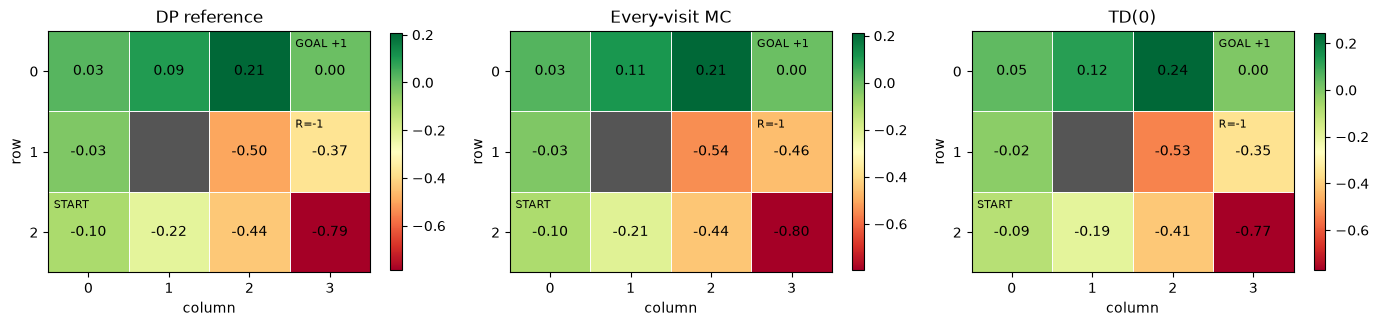

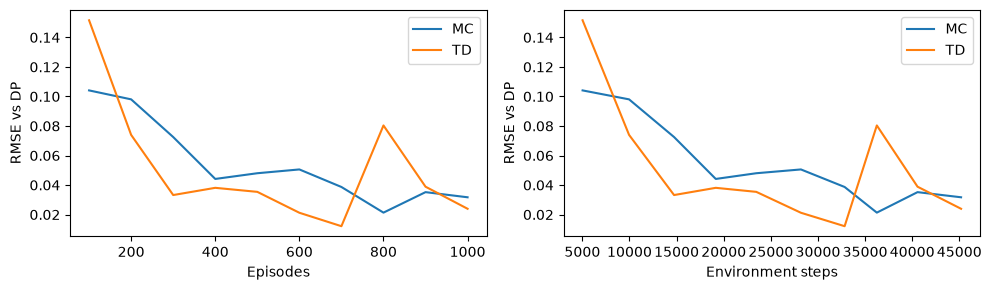

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, title, value in zip(axes, ('DP reference', 'Every-visit MC', 'TD(0)'), (reference.values, *values)):
    plot_grid(value, title=title, ax=ax)
plt.tight_layout(); plt.show()
history = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for column, label in ((2, 'MC'), (3, 'TD')):
    axes[0].plot(history[:, 0], history[:, column], label=label)
    axes[1].plot(history[:, 1], history[:, column], label=label)
axes[0].set(xlabel='Episodes', ylabel='RMSE vs DP')
axes[1].set(xlabel='Environment steps', ylabel='RMSE vs DP')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 5. B=1 Online와 B>1 Frozen Target Batch

`learn(batch)`는 **모든 Bootstrap Target을 갱신 전에 계산**한다. B>1에서 같은 상태가 반복되면
현재 V는 행 순서대로 갱신되지만 Target을 행 사이에 다시 계산하지 않는다.
위처럼 B=1로 호출하면 다음 전이의 Target은 이전 갱신을 반영한다.

예를 들어 V(1)=4, V(2)=10, γ=.9, α=.5이고 `(state,reward,next_state)`가 `(2,0,1)`, `(1,1,2)`이면
Batch의 error는 `[-6.4,6]`, 전이별 호출은 `[-6.4,3.12]`다. 두 계약은 회귀 테스트로 검증한다.

TD는 일반적인 Time-limit `truncated=True, terminated=False`에서 Bootstrap을 유지한다.
수집자가 reset된 관측 대신 실제 마지막 관측을 전달해야 한다. MC의 미완성 Episode 거절과 구분한다.
고정 α의 TD 오차와 표본 평균 MC 오차가 매 구간 감소하거나 특정 방법이 항상 우수할 필요는 없다.

## 6. SARSA — 실제 Next Action으로 Bootstrap

원본 sarsa.py는 Q(s′,a′)를 사용한다(γ=.9, α=.8, ε=.1, 10,000 Episode).
ModularRL은 Transition 필드를 바꾸지 않고 TabularSARSALearner.learn(batch, next_action=...)을 사용한다.
기존 TD(0)/Q-learning 실습 뒤의 §11에서 Step-by-step 학습과 비교를 실행한다.
실제 다음 행동을 선택한 뒤 학습하고, 그 행동을 다음 환경 step에서 그대로 실행한다.

## 7. Off-policy SARSA — 미구현 대응

원본 [`sarsa_off_policy.py`](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/ch06/sarsa_off_policy.py)는 target/behavior 정책의 비율로
TD Target을 보정한다(γ=.9, α=.8, ε=.1, 10,000 Episode).
행동 확률의 저장 시점과 보정 규칙을 포함한 별도 Learner 계약이 필요하다. 이 실습은 실행 지원하지 않는다.

## 8. Q-learning — `q_learning.py`

$$y=r+\gamma(1-\text{terminated})\max_aQ(s',a)$$

행동 선택은 ε-greedy `Model.act()`, 학습은 `TabularQLearner.learn()`가 담당한다.
고정 정책의 V Prediction과 달리 Q에서 학습 중의 정책을 개선한다.

In [6]:
q_model = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                EpsilonGreedyActionSelector(epsilon=.1)).double()
q_learner = TabularQLearner(q_model, TD0TargetGenerator(GAMMA), TabularQUpdateRule(alpha=.8))
Q_EPISODES, MAX_STEPS = 1000, 200
q_env = make_dlfs4_gridworld_env(max_episode_steps=MAX_STEPS)

환경은 동일한 Gymnasium reset/step API로 실행한다. Outcome 선택과 TimeLimit 처리를 Notebook에 구현하지 않는다.
학습 수식은 Learner가 담당한다. 원본의 10,000 Episode 대신 간소화 예제와 같은 1,000 Episode로 실행한다.

In [7]:
reward_history, truncated_episodes = [], 0
try:
    for number in range(Q_EPISODES):
        observation, info = q_env.reset(seed=SEED if number == 0 else None)
        total_reward = 0.
        while True:
            selected = q_model.act(observation)
            next_observation, reward, terminated, truncated, info = q_env.step(selected.action.item())
            transition = Transition(observation, selected.action, reward, next_observation,
                                    terminated, truncated, selected.log_prob)
            q_learner.learn(transition.to_batch())
            observation = next_observation
            total_reward += reward
            if terminated or truncated:
                break
        truncated_episodes += int(truncated)
        reward_history.append(total_reward)
finally:
    q_env.close()
print(f'Q-learning: episodes={Q_EPISODES} seed={SEED} gamma={GAMMA} alpha=.8 epsilon=.1')
print('truncated:', truncated_episodes, '| last 100 mean reward:', np.mean(reward_history[-100:]))

Q-learning: episodes=1000 seed=7 gamma=0.9 alpha=.8 epsilon=.1
truncated: 0 | last 100 mean reward: 1.0


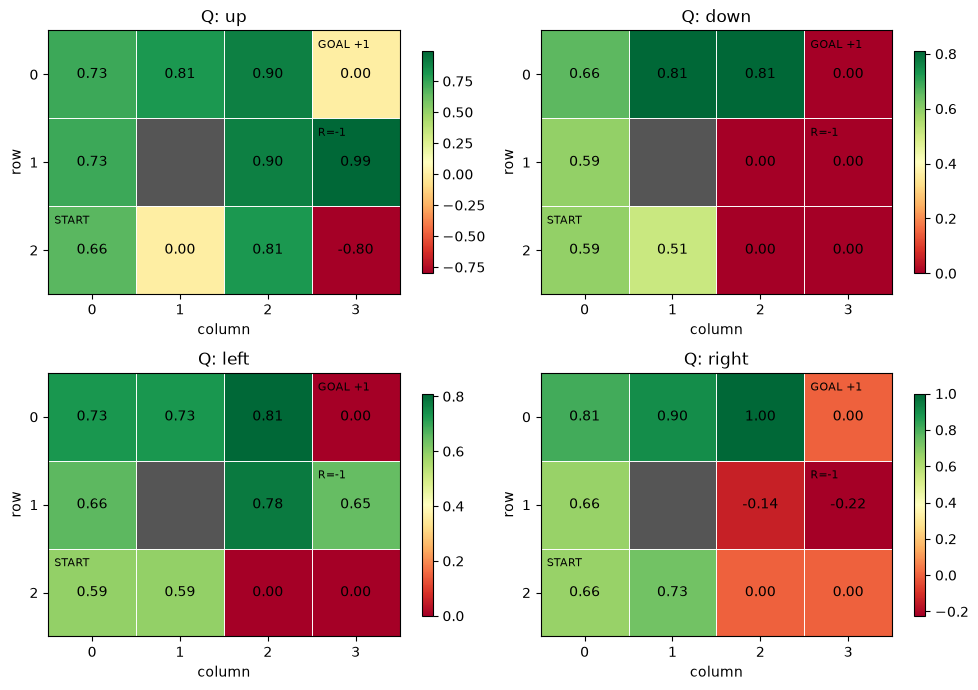

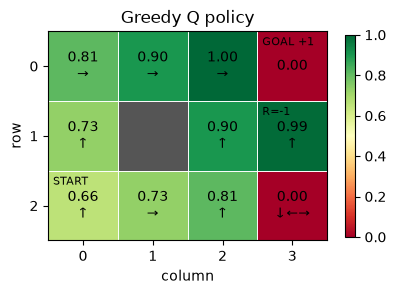

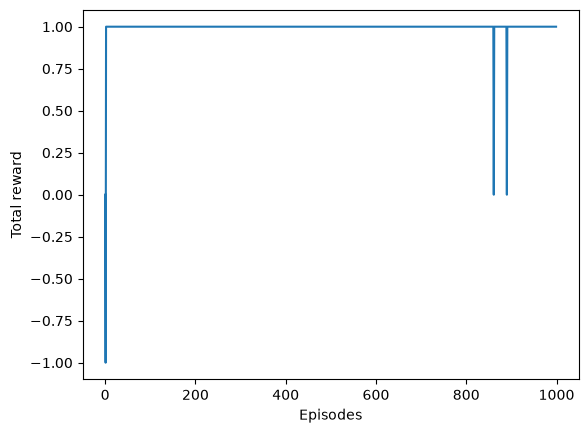

In [8]:
estimate = q_model.forward(states)
q_values = estimate.values.q[0].numpy()
greedy_policy = GreedyActionSelector().probabilities(estimate).numpy()
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for action, ax in enumerate(axes.flat):
    plot_grid(q_values[:, action], title=f'Q: {("up", "down", "left", "right")[action]}', ax=ax)
plt.tight_layout(); plt.show()
plot_grid(q_values.max(axis=-1), greedy_policy, title='Greedy Q policy')
plt.show()
plt.plot(reward_history)
plt.xlabel('Episodes'); plt.ylabel('Total reward'); plt.show()

## 9. Greedy Policy를 실행해 확인

In [9]:
eval_env = make_dlfs4_gridworld_env(max_episode_steps=20)
try:
    observation, info = eval_env.reset(seed=SEED)
    path = [DLFS4_STATES[observation]]
    while True:
        action = q_model.act(observation, deterministic=True).action.item()
        observation, reward, terminated, truncated, info = eval_env.step(action)
        path.append(DLFS4_STATES[observation])
        if terminated or truncated:
            break
finally:
    eval_env.close()
print('greedy path:', path, '| reached goal:', terminated)

greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)] | reached goal: True


## 10. `q_learning_simple.py`와의 대응

원본 두 Q-learning 예제의 업데이트는 같다. 위 Model + Learner가 두 예제를 함께 대체하므로
같은 학습 루프를 다시 복사하지 않는다. `Model.act()`는 행동과 Behavior log_prob를 함께 반환한다.
ModularRL의 학습 모드에서는 최대 Q 동률에 균등하게 탐색 확률을 주고 deterministic 모드는
가장 작은 인덱스를 택한다. 원본의 간소화 버전은 np.argmax로 첫 행동을 택한다.

SARSA·Off-policy SARSA의 미구현을 포함한 전체 대응 상태는 README 표에 기록했다.

고정 시작에서 방문이 적은 상태·행동의 Q는 0으로 남을 수 있다. 경로 성공이 모든 Q의 수렴을 뜻하지 않는다.

Env는 자연 종료 뒤 step을 거절한다. TimeLimit의 truncation 뒤에도 reset이 필요하며, 표준 Wrapper의 종료 flag를 보존한다. 정책 RNG와 Env RNG를 분리해 재실행 결정성을 검증한다.

## 11. SARSA — 실제 Next Action을 한 번 선택하고 그대로 실행

[Sutton & Barto Chapter 6](https://people.cs.umass.edu/~barto/courses/cs687/Chapter%206.pdf)의 On-policy TD Control이다.

$$y=r+\gamma(1-\mathrm{terminated})Q(s',a'),\quad\delta=y-Q(s,a)$$

Q-learning은 max Q(s′,·)를 사용하지만 SARSA는 **실제 행동 정책이 선택한 a′**를 사용한다.
TargetGenerator와 UpdateRule은 그대로 재사용한다. Learner 내부에서 행동을 선택하지 않는다.
Transition에 next_action을 추가하거나 Notebook에서 Target/Q 갱신을 재구현하지 않는다.

In [10]:
from modular_rl.learner import TabularSARSALearner

for next_action, terminated in ((1, False), (0, False), (None, True)):
    sarsa_demo_model = Model(IdentityRepresentation(), TabularQEstimator(4, 2)).double()
    sarsa_demo_model.estimator.q_table[1, 0] = 4
    sarsa_demo_model.estimator.q_table[2] = torch.tensor([10., 2.])
    sarsa_demo = TabularSARSALearner(sarsa_demo_model, TD0TargetGenerator(.9), TabularQUpdateRule(.5))
    error = sarsa_demo.learn(Transition(1, 0, 1., 2, terminated, False).to_batch(), next_action=next_action)
    print('next_action=', next_action, 'terminated=', terminated, 'TD error=', error.item(),
          'updated Q(1,0)=', sarsa_demo_model.estimator.q_table[1, 0].item())

next_action= 1 terminated= False TD error= -1.2000000000000002 updated Q(1,0)= 3.4
next_action= 0 terminated= False TD error= 6.0 updated Q(1,0)= 7.0
next_action= None terminated= True TD error= -3.0 updated Q(1,0)= 2.5


### Next Action과 Episode 경계

기본 next_action은 Batch와 같은 (B,) 정수 Tensor이며 B=1은 정수 scalar도 허용한다.
모든 행이 terminal이면 None을 허용한다. 혼합 Batch의 terminal 행에는 무시되는 유효 ID(예: 0)를 넣는다.
truncated-only는 마지막 관측에서 선택한 행동으로 Bootstrap하지만 그 행동을 종료된 환경에서 실행하지 않는다.
두 종료 flag가 모두 True면 Bootstrap하지 않는다. 실제 final observation은 수집자가 보존한다.

B>1은 모든 Target을 먼저 계산한 Frozen Target Batch Update다. 중복 쌍은 기존 Rule로 순차 갱신한다.
아래 Online SARSA는 B=1을 시간순으로 호출하고 a′를 학습 전에 선택해 다음 step까지 유지한다.

In [11]:
SARSA_EPISODES, SARSA_SEED, SARSA_ALPHA, SARSA_EPSILON = 1000, 7, .8, .1
torch.manual_seed(SARSA_SEED)
sarsa_model = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                    EpsilonGreedyActionSelector(SARSA_EPSILON)).double()
sarsa = TabularSARSALearner(sarsa_model, TD0TargetGenerator(GAMMA), TabularQUpdateRule(SARSA_ALPHA))
sarsa_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
sarsa_eval_env = make_dlfs4_gridworld_env(max_episode_steps=20)
sarsa_rewards, sarsa_lengths, sarsa_steps, sarsa_truncations = [], [], 0, 0
try:
    sarsa_before = collect_episode(sarsa_eval_env, lambda state: sarsa_model.act(state, deterministic=True).action.item(), seed=SARSA_SEED + 1)
    for number in range(SARSA_EPISODES):
        observation, _ = sarsa_env.reset(seed=SARSA_SEED if number == 0 else None)
        selected = sarsa_model.act(observation)
        episode_reward, episode_length = 0., 0
        while True:
            action = selected.action.item()
            log_prob = selected.log_prob.detach().cpu().clone()
            next_observation, reward, terminated, truncated, _ = sarsa_env.step(action)
            next_selected = None if terminated else sarsa_model.act(next_observation)
            next_action = None if next_selected is None else next_selected.action.item()
            transition = Transition(observation, action, reward, next_observation, terminated, truncated, log_prob)
            sarsa.learn(transition.to_batch(), next_action=next_action)
            episode_reward += reward
            episode_length += 1
            if terminated or truncated:
                break
            observation, selected = next_observation, next_selected  # Reuse the already selected action.
        sarsa_rewards.append(episode_reward)
        sarsa_lengths.append(episode_length)
        sarsa_steps += episode_length
        sarsa_truncations += int(truncated)
    sarsa_after = collect_episode(sarsa_eval_env, lambda state: sarsa_model.act(state, deterministic=True).action.item(), seed=SARSA_SEED + 1)
finally:
    sarsa_env.close()
    sarsa_eval_env.close()
print(f'SARSA: episodes={SARSA_EPISODES} steps={sarsa_steps} seed={SARSA_SEED} '
      f'gamma={GAMMA} alpha={SARSA_ALPHA} epsilon={SARSA_EPSILON} truncated={sarsa_truncations}')
print('before greedy: goal=', sarsa_before.terminated, 'steps=', len(sarsa_before))
print('after greedy: goal=', sarsa_after.terminated, 'steps=', len(sarsa_after), 'reward=', sum(t.reward.item() for t in sarsa_after.transitions))
print('last 100 training mean reward:', np.mean(sarsa_rewards[-100:]))

SARSA: episodes=1000 steps=8604 seed=7 gamma=0.9 alpha=0.8 epsilon=0.1 truncated=0
before greedy: goal= False steps= 20
after greedy: goal= True steps= 5 reward= 1.0
last 100 training mean reward: 1.0


### 같은 예산·설정으로 여러 Seed 비교

SARSA와 Q-learning은 서로 독립적인 Model/Learner/RNG 실행이다. 같은 Seed도 정책 변화와
행동 선택 시점이 달라 동일 Episode를 뜻하지 않는다. 두 알고리즘 모두 γ=.9, α=.8, ε=.1,
1,000 Episode를 사용한다. 작은 비교 루프는 환경 실행과 데이터 수집만 담당하며, 두 Learner의 공개 API로 학습한다.
학습 중 ε-greedy Reward/Length와 평가 시 Greedy Goal/Step을 구분한다.
고정 α와 유한 표본에서 한 Seed의 Greedy 평가가 실패할 수도 있다. 방법 간 성능 순위를 Assertion으로 고정하지 않는다.

In [12]:
from modular_rl.dp import value_iteration

comparison_optimal = value_iteration(mdp, gamma=GAMMA, theta=1e-12)

def run_td_control(algorithm, seed):
    """Small experiment loop: all target/update arithmetic stays in the learners."""
    torch.manual_seed(seed)
    model = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                  EpsilonGreedyActionSelector(SARSA_EPSILON)).double()
    learner_type = TabularSARSALearner if algorithm == 'sarsa' else TabularQLearner
    learner = learner_type(model, TD0TargetGenerator(GAMMA), TabularQUpdateRule(SARSA_ALPHA))
    train_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
    eval_env = make_dlfs4_gridworld_env(max_episode_steps=20)
    rewards, lengths = [], []
    try:
        for number in range(SARSA_EPISODES):
            observation, _ = train_env.reset(seed=seed if number == 0 else None)
            selected = model.act(observation)
            episode_reward, length = 0., 0
            while True:
                action = selected.action.item()
                next_observation, reward, terminated, truncated, _ = train_env.step(action)
                transition = Transition(observation, action, reward, next_observation, terminated, truncated)
                if algorithm == 'sarsa':
                    next_selected = None if terminated else model.act(next_observation)
                    learner.learn(transition.to_batch(), next_action=None if next_selected is None else next_selected.action.item())
                else:
                    learner.learn(transition.to_batch())
                    next_selected = None if terminated or truncated else model.act(next_observation)
                episode_reward += reward
                length += 1
                if terminated or truncated:
                    break
                observation, selected = next_observation, next_selected
            rewards.append(episode_reward)
            lengths.append(length)
        evaluation = collect_episode(eval_env, lambda state: model.act(state, deterministic=True).action.item(), seed=seed + 1)
    finally:
        train_env.close()
        eval_env.close()
    values = model.estimator.q_table.numpy().copy()
    return {'steps': sum(lengths), 'training_rewards': np.asarray(rewards), 'episode_lengths': np.asarray(lengths),
            'q_values': values, 'after': {'terminated': evaluation.terminated, 'steps': len(evaluation)},
            'max_q_rmse': np.sqrt(np.mean((values.max(axis=1)[nonterminal] - comparison_optimal.values[nonterminal])**2))}

comparison_results = {}
for comparison_seed in (7, 11, 19):
    for algorithm in ('sarsa', 'q_learning'):
        result = run_td_control(algorithm, comparison_seed)
        comparison_results[comparison_seed, algorithm] = result
        print(f"seed={comparison_seed} {algorithm}: steps={result['steps']} "
              f"train_reward(last100)={np.mean(result['training_rewards'][-100:]):.3f} "
              f"goal={result['after']['terminated']} greedy_steps={result['after']['steps']} "
              f"maxQ_DP_RMSE={result['max_q_rmse']:.6f}")
np.testing.assert_array_equal(sarsa_model.estimator.q_table.numpy(), comparison_results[7, 'sarsa']['q_values'])
print('Direct SARSA loop and comparison loop produce the same Q at seed 7.')

seed=7 sarsa: steps=8604 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.375808


seed=7 q_learning: steps=5738 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.230544


seed=11 sarsa: steps=6659 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.300900


seed=11 q_learning: steps=5630 train_reward(last100)=0.980 goal=True greedy_steps=5 maxQ_DP_RMSE=0.069670


seed=19 sarsa: steps=6627 train_reward(last100)=1.000 goal=False greedy_steps=20 maxQ_DP_RMSE=0.255833


seed=19 q_learning: steps=5611 train_reward(last100)=1.000 goal=True greedy_steps=5 maxQ_DP_RMSE=0.243963
Direct SARSA loop and comparison loop produce the same Q at seed 7.


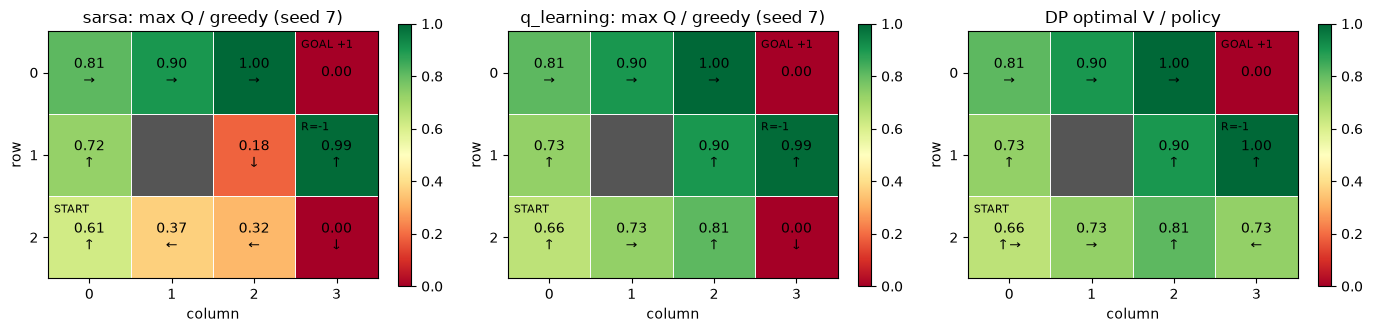

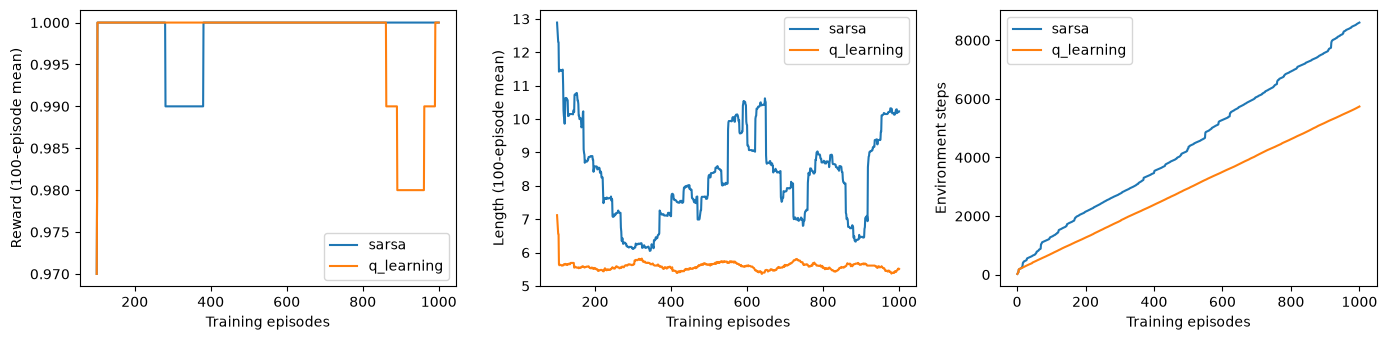

In [13]:
from modular_rl.dp import value_iteration

control_optimal = value_iteration(mdp, gamma=GAMMA, theta=1e-12)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, algorithm in zip(axes[:2], ('sarsa', 'q_learning')):
    values = comparison_results[7, algorithm]['q_values']
    policy = np.eye(mdp.n_actions)[values.argmax(axis=1)]
    plot_grid(values.max(axis=1), policy, title=f'{algorithm}: max Q / greedy (seed 7)', ax=ax)
plot_grid(control_optimal.values, control_optimal.policy, title='DP optimal V / policy', ax=axes[2])
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for algorithm in ('sarsa', 'q_learning'):
    result = comparison_results[7, algorithm]
    episodes = np.arange(1, SARSA_EPISODES + 1)
    axes[0].plot(episodes[99:], np.convolve(result['training_rewards'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[1].plot(episodes[99:], np.convolve(result['episode_lengths'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[2].plot(episodes, np.cumsum(result['episode_lengths']), label=algorithm)
for ax, label in zip(axes, ('Reward (100-episode mean)', 'Length (100-episode mean)', 'Environment steps')):
    ax.set(xlabel='Training episodes', ylabel=label)
    ax.legend()
plt.tight_layout(); plt.show()

SARSA는 탐색 행동도 Bootstrap에 포함하므로 학습 Q를 DP의 Q*와 같다고 가정하지 않는다.
이 비교의 RMSE는 Goal placeholder를 제외한 10개 상태의 max Q와 최적 V 차이다.
정확성은 실제 Next Action, 선택 횟수·실행 재사용, 종료 mask와 Batch/Online 차이의 결정적 테스트로 확인한다.
모델 저장·복원에는 기존 state_dict와 gamma/alpha·환경/행동 RNG 상태를 유지한다.
Off-policy SARSA와 n-step은 미구현이다. Expected SARSA는 다음 절의 예제 함수로 조합하며 라이브러리 Learner는 추가하지 않는다.

## 12. Expected SARSA — 기존 컴포넌트를 직접 조합

$$\bar Q(s')=\sum_a\pi(a\mid s')Q(s',a),\qquad
y=r+\gamma(1-\mathrm{terminated})\bar Q(s')$$

Q-learning은 max Q, SARSA는 실제 선택한 다음 행동의 Q, Expected SARSA는 행동 확률로 가중한 Q를 사용한다.
이번 실습은 **새 Learner와 새로운 TargetGenerator 없이** 실행한다.
`Model.forward → ActionSelector.probabilities → ΣπQ → TD0TargetGenerator → TabularQUpdateRule`을
작은 `examples/gridworld_expected_sarsa.py` 함수 한 곳에 작성했다. 아래 셀은 그 함수를 그대로 로드해 보여준다.
`examples`는 설치 패키지에 포함되지 않으므로 프로젝트 파일을 로드하며, sys.path나 라이브러리를 변경하지 않는다.

실제 행동을 고르는 Model의 **동일 Selector 객체**로 π를 조회한다. `probabilities()`는 행동을 샘플링하지 않고
RNG를 소비하지 않는다. 여기의 π는 학습 중 ε-greedy 정책이며 별도 Greedy 평가와 구분한다.
Q와 π는 한 번의 EstimatorOutput에서 읽고, Batch 전체의 Target을 갱신 전에 고정한다.

In [14]:
from pathlib import Path
import inspect
import runpy

expected_root = Path.cwd()
while not (expected_root / 'examples' / 'gridworld_expected_sarsa.py').is_file():
    if expected_root == expected_root.parent:
        raise FileNotFoundError('Open this tutorial inside the ModularRL project.')
    expected_root = expected_root.parent
expected_api = runpy.run_path(str(expected_root / 'examples' / 'gridworld_expected_sarsa.py'))
learn_expected_sarsa = expected_api['learn_expected_sarsa']
train_expected_comparison = expected_api['train_and_evaluate']
print(inspect.getsource(learn_expected_sarsa))

def learn_expected_sarsa(model: Model, batch: TransitionBatch, target_generator: TD0TargetGenerator,
                         update_rule: TabularQUpdateRule, *, policy_selector) -> Tensor:
    """Compose a frozen TD target and in-place Q update from an external batch.

    policy_selector must be the very object used by model.act, supporting
    discrete probabilities. Batch rows are (B,); states/actions are integer,
    rewards floating and boundary flags bool. Q/probabilities are (B,A) with
    equal dtype/device. The live table determines batch dtype/device.

    One estimate supplies both Q and pi before any writes. No action/RNG is
    sampled. Termination is masked by the existing target generator; time-limit
    truncation bootstraps from the collector's actual final observation.
    Existing sequential duplicate-pair updates return signed errors (B,) with
    no graph. This example function adds no library API or learning state.
    """
    _validate(model, batch, policy_selec

### ε와 종료 mask의 수치 검증

Q(s′,:)=[10,2], Q(s,a)=4, r=1, γ=.9, α=.5다.
ε=0이면 기대값은 10, ε=1이면 평균 6, ε=.2이면 π=[.9,.1]로 기대값은 9.2다.
동률 최대 행동에는 기존 Selector의 균등 Greedy 확률이 적용된다.
terminated는 Reward만 사용하고 truncated-only는 실제 마지막 관측에서 Bootstrap한다.
예제 함수는 no_grad에서 Target을 만들고 기존 Rule이 signed Error를 반환한다.

In [15]:
for epsilon, terminated, truncated in ((0., False, False), (1., False, False),
                                         (.2, False, False), (.2, True, False), (.2, False, True)):
    expected_demo = Model(IdentityRepresentation(), TabularQEstimator(3, 2),
                          EpsilonGreedyActionSelector(epsilon)).double()
    expected_demo.estimator.q_table[1, 0] = 4.
    expected_demo.estimator.q_table[2] = torch.tensor([10., 2.])
    rng_before = torch.random.get_rng_state().clone()
    error = learn_expected_sarsa(expected_demo, Transition(1, 0, 1., 2, terminated, truncated).to_batch(),
                                TD0TargetGenerator(.9), TabularQUpdateRule(.5),
                                policy_selector=expected_demo.action_selector)
    assert torch.equal(rng_before, torch.random.get_rng_state())
    print(f'epsilon={epsilon:.1f} terminated={terminated} truncated={truncated} '
          f'TD_error={error.item():.4f} Q={expected_demo.estimator.q_table[1, 0].item():.4f}; RNG unchanged')

epsilon=0.0 terminated=False truncated=False TD_error=6.0000 Q=7.0000; RNG unchanged
epsilon=1.0 terminated=False truncated=False TD_error=2.4000 Q=5.2000; RNG unchanged
epsilon=0.2 terminated=False truncated=False TD_error=5.2800 Q=6.6400; RNG unchanged
epsilon=0.2 terminated=True truncated=False TD_error=-3.0000 Q=2.5000; RNG unchanged
epsilon=0.2 terminated=False truncated=True TD_error=5.2800 Q=6.6400; RNG unchanged


### Gymnasium reset/step으로 B=1 Online 학습

다음은 첫 Episode를 직접 실행하는 흐름이다. 행동 샘플링과 환경 step은 호출자가 수행하고
수학적 계산은 위 예제 함수에만 있다. π 조회와 Q 업데이트가 끝난 뒤 다음 실행 행동을 샘플링한다.
SARSA의 학습 전 next_action 선택·유지와 달리 실제 a′가 Bootstrap에 필요하지 않다.
에피소드 경계에서 reset하고, truncated-only에서도 final observation을 그대로 사용한다.

In [16]:
torch.manual_seed(11)
expected_online = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                        EpsilonGreedyActionSelector(.1)).double()
expected_target, expected_update = TD0TargetGenerator(.9), TabularQUpdateRule(.8)
expected_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
expected_reward, expected_steps = 0., 0
try:
    observation, _ = expected_env.reset(seed=11)
    while True:
        selected = expected_online.act(observation)
        log_prob = selected.log_prob.detach().cpu().clone()
        next_observation, reward, terminated, truncated, _ = expected_env.step(selected.action.item())
        transition = Transition(observation, selected.action.item(), reward, next_observation,
                                terminated, truncated, log_prob)
        error = learn_expected_sarsa(expected_online, transition.to_batch(), expected_target, expected_update,
                                    policy_selector=expected_online.action_selector)
        expected_reward += reward
        expected_steps += 1
        if terminated or truncated:
            break
        observation = next_observation
finally:
    expected_env.close()
print(f'Expected SARSA online: episode=1 reward={expected_reward} length={expected_steps} '
      f'terminated={terminated} truncated={truncated}')

Expected SARSA online: episode=1 reward=1.0 length=41 terminated=True truncated=False


### 동일 하이퍼파라미터·Episode 예산으로 여러 Seed 비교

γ=.9, α=.8, ε=.1, 1,000 Episode, 시작 (2,0), 학습 TimeLimit 2,000 Step, Greedy 평가 20 Step이다.
세 방법은 독립 Model을 학습하며 동일 Seed가 동일 경험을 의미하지 않는다.
예제의 공통 환경 루프가 Expected SARSA 함수와 기존 Q-learning/SARSA Learner를 호출한다.
아래에서는 학습 코드를 다시 구현하지 않고 그 실험 함수를 사용한다.
Reward/Length와 누적 Step, 학습 후 Greedy 경로, DP 최적 경로, Q-table을 비교한다.

In [17]:
EXPECTED_EPISODES, EXPECTED_SEEDS = 1000, (7, 11, 19)
EXPECTED_ALGORITHMS = ('expected_sarsa', 'q_learning', 'sarsa')
expected_results = {}
for expected_seed in EXPECTED_SEEDS:
    for algorithm in EXPECTED_ALGORITHMS:
        _, result = train_expected_comparison(algorithm, episodes=EXPECTED_EPISODES, seed=expected_seed,
                                             gamma=.9, alpha=.8, epsilon=.1, max_steps=2000, log_every=0)
        expected_results[expected_seed, algorithm] = result
        print(f"seed={expected_seed} {algorithm}: episodes={result['episodes']} steps={result['steps']} "
              f"reward(last100)={np.mean(result['training_rewards'][-100:]):.3f} "
              f"length(last100)={np.mean(result['episode_lengths'][-100:]):.2f} "
              f"goal={result['after']['terminated']} greedy_steps={result['after']['steps']} "
              f"training_cutoff={result['truncated_episodes']} maxQ_DP_RMSE={result['max_q_rmse']:.6f}")
        print('Greedy path:', [DLFS4_STATES[state] for state in result['after']['path']])
        with np.printoptions(precision=4, suppress=True):
            print('Q (up/down/left/right):\n', result['q_values'])
print('DP optimal:', expected_results[7, 'expected_sarsa']['dp_steps'], 'steps, V(start)=.6561')
for algorithm in ('q_learning', 'sarsa'):
    for expected_seed in EXPECTED_SEEDS:
        np.testing.assert_array_equal(expected_results[expected_seed, algorithm]['q_values'],
                                      comparison_results[expected_seed, algorithm]['q_values'])
print('Q-learning/SARSA Q tables match the unchanged earlier exercise.')

seed=7 expected_sarsa: episodes=1000 steps=53664 reward(last100)=0.990 length(last100)=5.64 goal=True greedy_steps=5 training_cutoff=23 maxQ_DP_RMSE=0.260824
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.7033  0.6262  0.7033  0.7899]
 [ 0.7899  0.7899  0.7033  0.8871]
 [ 0.8871  0.7489  0.7899  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7033  0.5572  0.6262  0.6262]
 [ 0.8871  0.283   0.4463 -0.2189]
 [ 0.992   0.      0.     -0.2672]
 [ 0.6262  0.5572  0.5572  0.48  ]
 [ 0.377  -0.      0.5572  0.3397]
 [-0.0048 -0.0001  0.4687 -0.0144]
 [-0.8    -0.0144 -0.0003 -0.0147]]


seed=7 q_learning: episodes=1000 steps=5738 reward(last100)=1.000 length(last100)=5.51 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.230544
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.729   0.6561  0.729   0.81  ]
 [ 0.81    0.81    0.729   0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.5905  0.6561  0.6561]
 [ 0.9     0.      0.7774 -0.1395]
 [ 0.992   0.      0.648  -0.224 ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.      0.5102  0.5905  0.729 ]
 [ 0.81    0.      0.      0.    ]
 [-0.8     0.      0.      0.    ]]


seed=7 sarsa: episodes=1000 steps=8604 reward(last100)=1.000 length(last100)=10.23 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.375808
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5416  0.3011  0.2856  0.8098]
 [ 0.7126  0.7904  0.5141  0.9   ]
 [ 0.9     0.161   0.572   1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7236  0.2501  0.3005  0.3242]
 [ 0.      0.1845  0.     -0.2688]
 [ 0.992   0.      0.     -0.224 ]
 [ 0.6147  0.22    0.2979  0.4399]
 [ 0.331   0.1493  0.3687  0.1367]
 [ 0.0339  0.1093  0.3228  0.    ]
 [-0.8     0.      0.      0.    ]]


seed=11 expected_sarsa: episodes=1000 steps=5592 reward(last100)=0.950 length(last100)=5.39 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.050405
Greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.      0.497   0.      0.7378]
 [ 0.      0.      0.      0.8863]
 [ 0.8863  0.7666  0.7378  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.6254  0.      0.      0.    ]
 [ 0.8863  0.6804  0.7668 -0.1565]
 [ 1.      0.      0.6133  0.    ]
 [ 0.5206  0.5403  0.5404  0.6059]
 [ 0.6059  0.6059  0.5404  0.6805]
 [ 0.7669  0.6805  0.6059  0.582 ]
 [-0.1726  0.4373  0.6804  0.443 ]]


seed=11 q_learning: episodes=1000 steps=5630 reward(last100)=0.980 length(last100)=5.44 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.069670
Greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.      0.      0.      0.6387]
 [ 0.4147  0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.5905  0.      0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.648   0.    ]
 [ 0.5314  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.729   0.6561  0.6561]
 [-0.128   0.5249  0.729   0.    ]]


seed=11 sarsa: episodes=1000 steps=6659 reward(last100)=1.000 length(last100)=6.75 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.300900
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5115  0.4444  0.4909  0.81  ]
 [ 0.5825  0.627   0.4908  0.9   ]
 [ 0.9     0.81    0.6927  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7266  0.3537  0.363   0.3952]
 [ 0.9     0.4478  0.5746 -0.8512]
 [ 0.      0.4392  0.      0.    ]
 [ 0.6279  0.368   0.3747  0.2974]
 [ 0.3169  0.3242  0.3674  0.3146]
 [-0.5436  0.0082  0.359   0.0912]
 [ 0.      0.0253  0.223   0.0253]]


seed=19 expected_sarsa: episodes=1000 steps=5621 reward(last100)=1.000 length(last100)=5.49 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.305310
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.7033  0.6262  0.7033  0.7899]
 [ 0.7899  0.7899  0.7033  0.8871]
 [ 0.8871  0.7505  0.7899  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7033  0.5568  0.6262  0.6262]
 [ 0.8871  0.      0.5303  0.    ]
 [ 0.      0.      0.4301  0.    ]
 [ 0.6262  0.5568  0.5568  0.4635]
 [-0.     -0.      0.5568 -0.0003]
 [ 0.6004 -0.0003 -0.     -0.0144]
 [-0.8     0.     -0.0003 -0.0144]]


seed=19 q_learning: episodes=1000 steps=5611 reward(last100)=1.000 length(last100)=5.49 goal=True greedy_steps=5 training_cutoff=0 maxQ_DP_RMSE=0.243963
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.729   0.6561  0.729   0.81  ]
 [ 0.81    0.81    0.729   0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.5905  0.6561  0.6561]
 [ 0.9     0.5832  0.     -0.4417]
 [ 0.      0.      0.7475  0.    ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.      0.      0.4724  0.729 ]
 [ 0.81    0.      0.      0.    ]
 [-0.8     0.      0.      0.    ]]


seed=19 sarsa: episodes=1000 steps=6627 reward(last100)=1.000 length(last100)=5.94 goal=False greedy_steps=20 training_cutoff=0 maxQ_DP_RMSE=0.255833
Greedy path: [(2, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0)]
Q (up/down/left/right):
 [[ 0.5218  0.5627  0.5832  0.4696]
 [ 0.5525  0.5286  0.5612  0.8398]
 [ 0.9     0.81    0.6258  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.5489  0.4225  0.5895  0.5717]
 [ 0.9     0.      0.648  -0.1088]
 [ 0.992   0.      0.      0.    ]
 [ 0.6346  0.3672  0.3843  0.3694]
 [ 0.2927  0.2114  0.5524  0.2622]
 [ 0.6804  0.      0.     -0.576 ]
 [-0.384   0.      0.      0.    ]]
DP optimal: 5 steps, V(start)=.6561
Q-learning/SARSA Q tables match the unchanged earlier exercise.


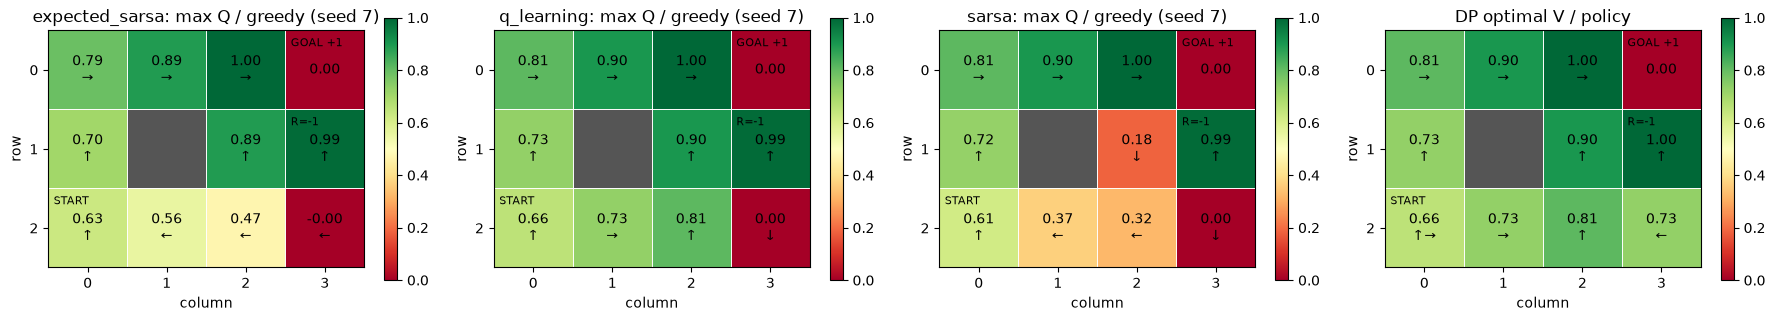

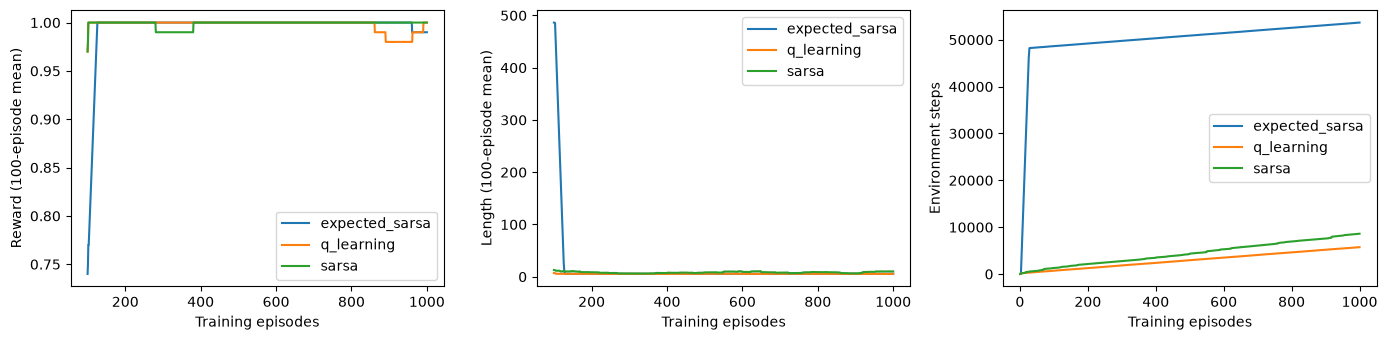

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, algorithm in zip(axes[:3], EXPECTED_ALGORITHMS):
    q = expected_results[7, algorithm]['q_values']
    greedy = np.eye(mdp.n_actions)[q.argmax(axis=1)]
    plot_grid(q.max(axis=1), greedy, title=f'{algorithm}: max Q / greedy (seed 7)', ax=ax)
plot_grid(control_optimal.values, control_optimal.policy, title='DP optimal V / policy', ax=axes[3])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for algorithm in EXPECTED_ALGORITHMS:
    result = expected_results[7, algorithm]
    episodes = np.arange(1, EXPECTED_EPISODES + 1)
    axes[0].plot(episodes[99:], np.convolve(result['training_rewards'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[1].plot(episodes[99:], np.convolve(result['episode_lengths'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[2].plot(episodes, np.cumsum(result['episode_lengths']), label=algorithm)
for ax, label in zip(axes, ('Reward (100-episode mean)', 'Length (100-episode mean)', 'Environment steps')):
    ax.set(xlabel='Training episodes', ylabel=label)
    ax.legend()
plt.tight_layout(); plt.show()

Expected SARSA의 세 Seed 모두 학습 후 5 Step/+1로 목표에 도달했다. Seed 7은 학습 초기에 23 Episode가
Time-limit으로 잘려 Step 비용이 컸다. SARSA Seed 19의 Greedy cutoff도 그대로 표시한다.
고정 α·유한 표본에서 순위나 모든 Q의 수렴을 보장하지 않는다. Expected/SARSA의 ε-greedy Q를 Q*와
동일하다고 간주하지 않으며, max Q와 최적 V의 RMSE는 비교 지표다.

기존 Learner의 Bootstrap은 max/gather로 고정돼 있다. 이번 검증은 **출력 계약은 재사용 가능하지만
Learner의 조합 경로는 고정돼 있음**을 보여준다. TD0TargetGenerator는 이미 계산된 next_value만 받으므로
새 TargetGenerator로 π/Q 선택 책임을 옮길 필요가 없다. 향후 공통화 후보는 외부에서 계산한 next_value (B,)를
받는 작은 Tabular Target/Update 조합이며, 이번에는 그 인터페이스나 공통 Base Class를 추가하지 않는다.
예제에는 학습 상태가 따로 없고 Q/ε는 Model.state_dict에 포함된다. 재개 시 γ/α와 환경·Torch RNG도 보존한다.

## 13. Double Q-learning — 선택과 평가를 서로 다른 Q로 수행

Q-learning은 같은 추정치로 최댓값 행동을 고르고 그 가치를 평가한다.
추정 오차가 있는 행동들 중 큰 값을 선택하면 Max가 실제 가치보다 커질 수 있다(Maximization Bias).
Double Q-learning은 두 개의 독립 Q-table을 두고 선택과 평가를 교차한다.

$$a^*=\arg\max_a Q_1(s',a),\quad y_1=r+\gamma(1-\mathrm{terminated})Q_2(s',a^*)$$
$$Q_1(s,a)\leftarrow Q_1(s,a)+\alpha[y_1-Q_1(s,a)]$$

Q₂ 갱신은 두 역할을 바꾼다. 매 Step마다 독립 동전을 던져 **하나의 테이블만** 갱신한다.
Behavior와 Greedy 평가에는 **Q₁+Q₂**를 사용한다. Bootstrap argmax 동률은 최소 행동 ID,
Behavior 동률은 기존 Selector의 균등 샘플링이다.

새 Learner나 합산용 영구 Q-table을 만들지 않는다. 기존 Model.forward 두 결과를 더해
`EstimatorOutput(values=ValueOutput(q=(q1+q2,)))`로 기존 Selector에 전달한다.
기존 Model.act는 하나의 Estimator를 사용하므로 여기서는 Selector.select를 공개 API로 직접 호출한다.
다음 셀은 예제 파일의 같은 함수를 로드해 표시한다. Notebook에서 교차 Target 계산을 다시 정의하지 않는다.

In [19]:
double_root = Path.cwd()
while not (double_root / 'examples' / 'gridworld_double_q_learning.py').is_file():
    if double_root == double_root.parent:
        raise FileNotFoundError('Open this tutorial inside the ModularRL project.')
    double_root = double_root.parent
double_api = runpy.run_path(str(double_root / 'examples' / 'gridworld_double_q_learning.py'))
combined_estimate = double_api['combined_estimate']
act_double_q = double_api['act_double_q']
choose_update_first = double_api['choose_update_first']
learn_double_q = double_api['learn_double_q']
train_double_comparison = double_api['train_and_evaluate']
for function in (combined_estimate, act_double_q, learn_double_q):
    print(inspect.getsource(function))

@torch.no_grad()
def combined_estimate(model1: Model, model2: Model, observation) -> EstimatorOutput:
    """Combine live Q estimates into one explicit Q sum, without a third table.

    Integer observations may be single or batched. The result has Q shape
    (..., A). The existing selector receives one tensor, not two unreduced
    critics. Behavior and greedy evaluation both use Q1 + Q2.
    """
    _validate_models(model1, model2)
    q1, = model1.forward(observation).values.q
    q2, = model2.forward(observation).values.q
    if q1.shape != q2.shape:
        raise ValueError("Q estimates must have the same shape without broadcasting")
    return EstimatorOutput(values=ValueOutput(q=(q1 + q2,)))

def act_double_q(model1: Model, model2: Model, observation, selector: EpsilonGreedyActionSelector,
                 *, deterministic=False) -> ActionOutput:
    """Use the unchanged selector's sampling, ties, probabilities and log_prob."""
    return selector.select(combined_estimate(model

### 교차 Bootstrap 수치 검증

Q₁(s′,:)=[10,2], Q₂(s′,:)=[1,7], 현재 Q₁(s,a)=4, Q₂(s,a)=6이다.
r=1, γ=.9, α=.5에서 Q₁을 갱신하면 a*=0, Bootstrap=1, Target=1.9,
Error=−2.1, 새 Q₁=2.95다. Q₂ 갱신은 a*=1, Bootstrap=2,
Target=2.8, Error=−3.2, 새 Q₂=4.4다. 반대 테이블은 유지한다.

In [20]:
for update_first in (True, False):
    double_demo = tuple(Model(IdentityRepresentation(), TabularQEstimator(3, 2)).double() for _ in range(2))
    double_demo[0].estimator.q_table[1, 0] = 4.
    double_demo[1].estimator.q_table[1, 0] = 6.
    double_demo[0].estimator.q_table[2] = torch.tensor([10., 2.])
    double_demo[1].estimator.q_table[2] = torch.tensor([1., 7.])
    other = double_demo[1 if update_first else 0].estimator.q_table.clone()
    error = learn_double_q(*double_demo, Transition(1, 0, 1., 2, False, False).to_batch(),
                          TD0TargetGenerator(.9), TabularQUpdateRule(.5), update_first=update_first)
    torch.testing.assert_close(double_demo[1 if update_first else 0].estimator.q_table, other, rtol=0, atol=0)
    print(f'update_first={update_first}: TD_error={error.item():.4f} '
          f'Q1={double_demo[0].estimator.q_table[1, 0].item():.4f} '
          f'Q2={double_demo[1].estimator.q_table[1, 0].item():.4f}; other table unchanged')

update_first=True: TD_error=-2.1000 Q1=2.9500 Q2=6.0000; other table unchanged
update_first=False: TD_error=-3.2000 Q1=4.0000 Q2=4.4000; other table unchanged


### Gymnasium Step-by-step Online 학습과 RNG

환경은 reset(seed=seed)의 자체 NumPy RNG, 행동은 torch.manual_seed(seed)의 PyTorch RNG,
갱신 대상은 별도 default_rng(seed+2)를 사용한다. Evaluation은 deterministic으로 두 학습 RNG를 소비하지 않는다.
다음은 한 Episode를 직접 학습한다. Behavior log_prob은 Q₁+Q₂의 sampling-time 값이다.
terminated에서만 Bootstrap을 제거하고 truncated-only에서는 실제 마지막 관측을 사용한다.
B>1 호출을 사용할 때 update_first는 Batch 전체의 한 테이블을 지정하며 모든 Target은 첫 갱신 전에 고정된다.

In [21]:
torch.manual_seed(11)
double_models = tuple(Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions)).double() for _ in range(2))
double_selector = EpsilonGreedyActionSelector(.1).double()
double_target, double_update = TD0TargetGenerator(.9), TabularQUpdateRule(.8)
double_update_rng = np.random.default_rng(13)
double_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
double_reward, double_steps, double_counts = 0., 0, [0, 0]
try:
    observation, _ = double_env.reset(seed=11)
    while True:
        selected = act_double_q(*double_models, observation, double_selector)
        log_prob = selected.log_prob.detach().cpu().clone()
        next_observation, reward, terminated, truncated, _ = double_env.step(selected.action.item())
        transition = Transition(observation, selected.action.item(), reward, next_observation, terminated, truncated, log_prob)
        update_first = choose_update_first(double_update_rng)
        error = learn_double_q(*double_models, transition.to_batch(), double_target, double_update, update_first=update_first)
        double_counts[0 if update_first else 1] += 1
        double_reward += reward
        double_steps += 1
        if terminated or truncated:
            break
        observation = next_observation
finally:
    double_env.close()
print(f'Double Q online: episode=1 reward={double_reward} length={double_steps} '
      f'terminated={terminated} truncated={truncated} Q1/Q2_updates={double_counts}')

Double Q online: episode=1 reward=1.0 length=41 terminated=True truncated=False Q1/Q2_updates=[16, 25]


### Q-learning과 동일 예산으로 비교

γ=.9, α=.8, ε=.1, 각 1,000 Episode, Seed7/11/19다. Double Q는 독립 환경에서 새로 학습하고,
Q-learning/SARSA/Expected SARSA는 §12에서 동일 설정으로 실행한 결과를 그대로 재사용한다.
동일 Seed가 동일 경험을 의미하지 않는다. 학습 Reward/Length와 Greedy 평가를 구분한다.

행동에는 Q₁+Q₂를 쓰지만 가치 비교에는 **max((Q₁+Q₂)/2)**를 사용한다.
합산 Q 자체를 DP V*와 비교하면 스케일이 두 배가 되어 의미가 달라진다.

In [22]:
double_results = {}
for double_seed in (7, 11, 19):
    _, result = train_double_comparison(episodes=1000, seed=double_seed, gamma=.9, alpha=.8,
                                       epsilon=.1, max_steps=2000, log_every=0)
    double_results[double_seed] = result
    print(f"seed={double_seed} double_q: episodes={result['episodes']} steps={result['steps']} "
          f"reward(last100)={np.mean(result['training_rewards'][-100:]):.3f} "
          f"length(last100)={np.mean(result['episode_lengths'][-100:]):.2f} "
          f"goal={result['after']['terminated']} greedy_steps={result['after']['steps']} "
          f"training_cutoff={result['truncated_episodes']} avgQ_DP_RMSE={result['max_q_rmse']:.9g} "
          f"Q1/Q2_updates={result['update_counts'].tolist()}")
    print('Double Q greedy path:', [DLFS4_STATES[state] for state in result['after']['path']])
    print('DP optimal path:', [DLFS4_STATES[state] for state in result['dp_path']])
    with np.printoptions(precision=4, suppress=True):
        print('Q1 (up/down/left/right):\n', result['q1_values'])
        print('Q2 (up/down/left/right):\n', result['q2_values'])
    for algorithm in ('q_learning', 'sarsa', 'expected_sarsa'):
        reference_run = expected_results[double_seed, algorithm]
        print(f"  {algorithm}: steps={reference_run['steps']} reward(last100)={np.mean(reference_run['training_rewards'][-100:]):.3f} "
              f"length(last100)={np.mean(reference_run['episode_lengths'][-100:]):.2f} "
              f"goal={reference_run['after']['terminated']} greedy_steps={reference_run['after']['steps']} "
              f"maxQ_DP_RMSE={reference_run['max_q_rmse']:.6f}")

seed=7 double_q: episodes=1000 steps=6017 reward(last100)=0.990 length(last100)=5.62 goal=True greedy_steps=5 training_cutoff=0 avgQ_DP_RMSE=2.44923734e-09 Q1/Q2_updates=[3044, 2973]
Double Q greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q1 (up/down/left/right):
 [[ 0.      0.      0.      0.81  ]
 [ 0.      0.      0.5832  0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.4724  0.4829  0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.5207  0.     -0.08  ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.7288  0.6561  0.6561]
 [-0.0802 -0.576   0.729   0.6068]]
Q2 (up/down/left/right):
 [[ 0.5832  0.      0.      0.81  ]
 [ 0.648   0.648   0.5832  0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.      0.      0.5244]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.     -0.8  

seed=11 double_q: episodes=1000 steps=5790 reward(last100)=0.990 length(last100)=5.58 goal=True greedy_steps=5 training_cutoff=0 avgQ_DP_RMSE=0.148031751 Q1/Q2_updates=[2872, 2918]
Double Q greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q1 (up/down/left/right):
 [[ 0.      0.      0.      0.    ]
 [ 0.4977  0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.5905  0.      0.    ]
 [ 0.9     0.729   0.8097 -0.1   ]
 [ 1.      0.      0.648   0.    ]
 [ 0.5314  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.729   0.6561  0.6561]
 [-0.24    0.5249  0.729   0.    ]]
Q2 (up/down/left/right):
 [[ 0.      0.      0.      0.7257]
 [ 0.622   0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.5905  0.      0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.      0.    ]

seed=19 double_q: episodes=1000 steps=5796 reward(last100)=0.970 length(last100)=5.44 goal=True greedy_steps=5 training_cutoff=0 avgQ_DP_RMSE=1.39409542e-08 Q1/Q2_updates=[2868, 2928]
Double Q greedy path: [(2, 0), (2, 1), (2, 2), (1, 2), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q1 (up/down/left/right):
 [[ 0.      0.      0.      0.81  ]
 [ 0.648   0.      0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.4724  0.      0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.648   0.    ]
 [ 0.6561  0.5905  0.5905  0.6561]
 [ 0.6561  0.6561  0.5905  0.729 ]
 [ 0.81    0.729   0.6561  0.6561]
 [-0.24    0.      0.729   0.    ]]
Q2 (up/down/left/right):
 [[ 0.      0.      0.5832  0.81  ]
 [ 0.      0.648   0.      0.9   ]
 [ 0.9     0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.4724  0.4025  0.    ]
 [ 0.9     0.729   0.81   -0.1   ]
 [ 1.      0.      0.      0.  

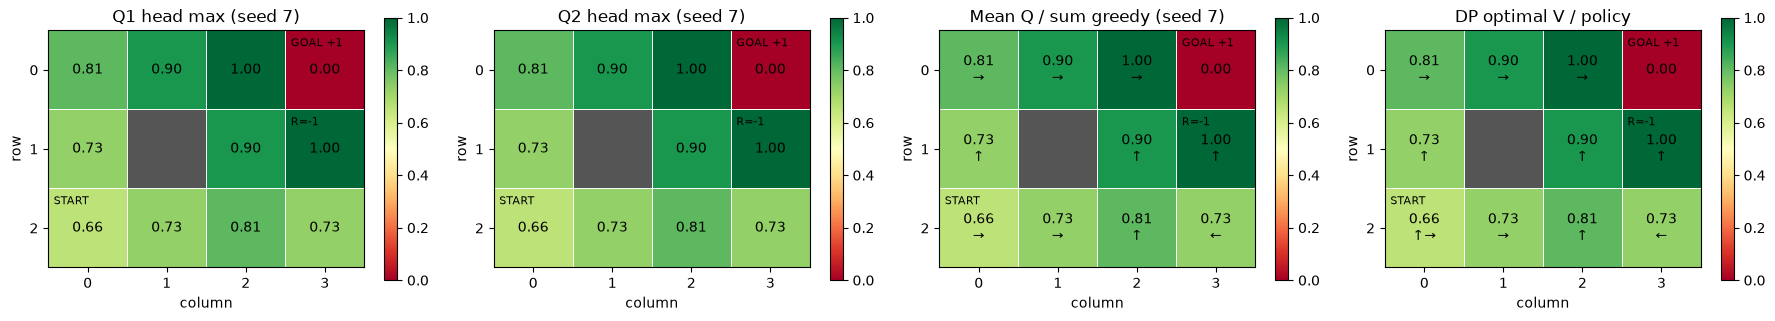

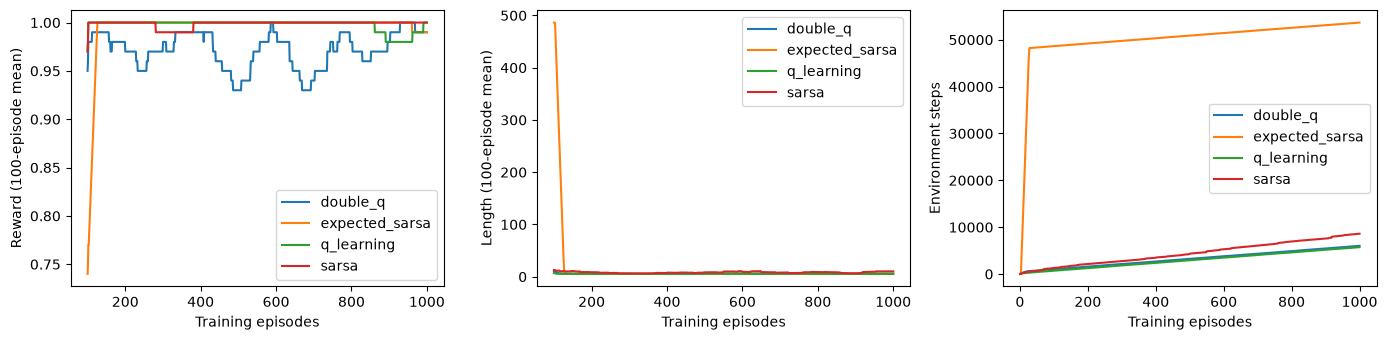

In [23]:
double_display = double_results[7]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
plot_grid(double_display['q1_values'].max(axis=1), title='Q1 head max (seed 7)', ax=axes[0])
plot_grid(double_display['q2_values'].max(axis=1), title='Q2 head max (seed 7)', ax=axes[1])
sum_q = double_display['q1_values'] + double_display['q2_values']
sum_greedy = np.eye(mdp.n_actions)[sum_q.argmax(axis=1)]
plot_grid(double_display['q_values'].max(axis=1), sum_greedy, title='Mean Q / sum greedy (seed 7)', ax=axes[2])
plot_grid(control_optimal.values, control_optimal.policy, title='DP optimal V / policy', ax=axes[3])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
comparison_runs = {'double_q': double_display, **{algorithm: expected_results[7, algorithm] for algorithm in EXPECTED_ALGORITHMS}}
for algorithm, result in comparison_runs.items():
    episodes = np.arange(1, len(result['episode_lengths']) + 1)
    axes[0].plot(episodes[99:], np.convolve(result['training_rewards'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[1].plot(episodes[99:], np.convolve(result['episode_lengths'], np.ones(100)/100, mode='valid'), label=algorithm)
    axes[2].plot(episodes, np.cumsum(result['episode_lengths']), label=algorithm)
for ax, label in zip(axes, ('Reward (100-episode mean)', 'Length (100-episode mean)', 'Environment steps')):
    ax.set(xlabel='Training episodes', ylabel=label)
    ax.legend()
plt.tight_layout(); plt.show()

### Maximization Bias 교재 실험의 표현 한계

[Sutton & Barto §6.7, Example 6.7, pp.134–136](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=156)의
A에는 두 행동이 있다. right는 보상 0으로 종료하고 left는 보상 0으로 B에 간다.
B의 여러 행동은 평균 −.1·분산 1의 정규분포 보상으로 종료한다.

현재 TabularMDP는 유한 Outcome의 **고정 Scalar 보상**과 모든 상태의 **동일 행동 수**를 표현한다.
TabularEnv에는 연속 Reward Sampler와 상태별 유효 행동 mask가 없다. 원본 분포/정책을 정확히
재현하려면 이 계약을 확장해야 하므로 이번 실험은 제외한다. 유한 보상 근사나 중복 행동을 원본 실험으로 부르지 않는다.
Gridworld 결과만으로 Maximization Bias가 일반적으로 제거됐다고 결론내리지 않는다.

두 Model과 기존 Selector/TargetGenerator/UpdateRule은 재사용할 수 있었다. Model은 하나의 Estimator를
조합하므로 두 forward 결과를 합산하는 예제 함수가 필요했고, 추가 클래스나 동기화용 Q-table은 필요 없었다.
향후 최소 공통화 후보는 명시적인 Q 출력 결합 함수와 외부 next_value를 받는 Target/Update 조합이다.
이번에는 라이브러리 인터페이스나 공통 프레임워크를 추가하지 않는다.

Checkpoint는 두 Model.state_dict, 별도 Selector.state_dict(ε), γ/α, Torch RNG, 갱신 RNG를 함께 저장한다.
환경 실행을 재개할 때는 환경 RNG와 Episode 위치도 수집자가 관리한다. 이번 함수에는 숨겨진 Learner 통계가 없다.
유한 표본의 성능 순위를 고정하지 않고 수학·독립 저장 공간·갱신 횟수·확률·복원 재현성을 결정적으로 검증한다.

## 14. Online n-step SARSA — Chapter 7의 시간 연결 검증

앞선 실습 셀과 출력은 유지하고 [Sutton & Barto §7.2](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=169)의
Online n-step SARSA를 예제 함수로 조합한다.

$$G_{\tau:\tau+n}=\sum_{k=1}^{m}\gamma^{k-1}R_{\tau+k}
+\gamma^m Q(S_{\tau+m},A_{\tau+m})$$

자연 종료는 Bootstrap을 제외한다. Time-limit으로 짧아진 꼬리는 실제 보상 수 m을 쓰며,
마지막 관측의 **이미 선택한** 행동으로 Bootstrap한다. terminated가 우선하므로 두 flag가 True여도 Bootstrap하지 않는다.

현재 저장소에는 TDNTargetGenerator, SequenceReplayBuffer, n-step DQN이 없다.
기존 TD0TargetGenerator의 `reward + gamma * continuation`을 역순으로 합성하면 같은 n-step Return이 된다.
새 Target/Learner 클래스를 만들거나 공개 API를 바꾸지 않는다.
ReplayBuffer의 무작위 행으로 시간 순서를 추측하지 않고, `deque`에 owned B=1 TransitionBatch를 보관한다.
Episode는 전체 완료 경험에 적합하지만 여기서는 완료 전에 학습해야 하므로 collect_episode로 훈련하지 않는다.

In [24]:
nstep_root = Path.cwd()
while not (nstep_root / 'examples' / 'gridworld_n_step_sarsa.py').is_file():
    if nstep_root == nstep_root.parent:
        raise FileNotFoundError('Open this tutorial inside the ModularRL project.')
    nstep_root = nstep_root.parent
nstep_api = runpy.run_path(str(nstep_root / 'examples' / 'gridworld_n_step_sarsa.py'))
learn_nstep = nstep_api['learn_n_step_sarsa']
run_nstep_episode = nstep_api['run_episode']
train_nstep = nstep_api['train_and_evaluate']
for function in (learn_nstep, run_nstep_episode):
    print(inspect.getsource(function))

def learn_n_step_sarsa(model: Model, window, target_generator: TD0TargetGenerator,
                       update_rule: TabularQUpdateRule, *, next_action=None) -> Tensor:
    """Update only the oldest row of an ordered window of B=1 batches.

    Window length is the actual reward count m, not a nominal fixed n.
    Contiguous rows cannot cross an episode boundary. next_action is the
    actual action already selected at the last next observation; scalar or
    (1,) integer IDs are accepted. None is valid only for natural termination.

    The caller owns window storage and removes its oldest row after success.
    Each call reads current Q under no_grad, then composes the existing TD0
    backup in reverse reward order. This yields gamma**m bootstrap, including
    shortened time-limit tails. Natural termination dominates truncation.
    Flush calls re-evaluate Q independently after earlier writes, retaining
    the same final selected action. Signed error (1,) follows table dtype/dev

### Return과 짧은 Episode의 수치 검증

n=3, γ=.9, rewards=[1,2,3], 실제 선택한 끝점 행동의 Q=4이면 Target은 8.146이다.
짧은 자연 종료 [1,2]는 [2.8,2.0], Time-limit은 [6.04,5.6]이다.
끝점의 다른 행동에 Q=100을 놓아 Max 대신 실제 선택 행동을 읽는지도 확인한다.
아래는 같은 예제 함수를 호출하고 α=1의 갱신 후 Q를 Target으로 표시한다.

In [25]:
from collections import deque

for rewards, terminated, truncated, expected in (([1,2,3], False, False, [8.146]),
                                                ([1,2], True, False, [2.8,2.]),
                                                ([1,2], False, True, [6.04,5.6]),
                                                ([1,2], True, True, [2.8,2.])):
    nstep_demo = Model(IdentityRepresentation(), TabularQEstimator(4, 2)).double()
    nstep_demo.estimator.q_table[len(rewards)] = torch.tensor([100., 4.])
    pending_demo = deque(Transition(i, 0, float(r), i+1, terminated and i==len(rewards)-1,
                                    truncated and i==len(rewards)-1).to_batch() for i,r in enumerate(rewards))
    targets = []
    while pending_demo:
        state = pending_demo[0].observation.item()
        learn_nstep(nstep_demo, pending_demo, TD0TargetGenerator(.9), TabularQUpdateRule(1.),
                    next_action=None if terminated else 1)
        targets.append(nstep_demo.estimator.q_table[state, 0].item())
        pending_demo.popleft()
        if not (terminated or truncated):
            break  # An open normal window learns only one head, not an episode flush.
    np.testing.assert_allclose(targets, expected, rtol=1e-12, atol=1e-12)
    print(f'rewards={rewards} terminated={terminated} truncated={truncated} targets={np.round(targets, 6).tolist()}')

rewards=[1, 2, 3] terminated=False truncated=False targets=[8.146]
rewards=[1, 2] terminated=True truncated=False targets=[2.8, 2.0]
rewards=[1, 2] terminated=False truncated=True targets=[6.04, 5.6]
rewards=[1, 2] terminated=True truncated=True targets=[2.8, 2.0]


### Online 업데이트 시점과 Next Action 재사용

매 Step에서 저장한 Aₜ를 실행하고, 자연 종료가 아니면 Aₜ₊₁를 **갱신 전에 한 번** 선택한다.
이 행동은 다음 step에서 그대로 실행한다. n개 전이가 모이면 τ=t−n+1의 가장 오래된 행 하나를 갱신한다.
n=3, T=5는 3번째 Step에서 첫 갱신, 4·5번째 Step에서 다음 두 갱신을 하고 끝난 뒤 마지막 두 행을 처리한다.
잔여 처리는 추가 step/act 없이 수행한다. n=1은 기존 SARSA의 타이밍·RNG·수치와 정확히 같다.

Truncation의 A_T는 선택만 하고 실행하지 않는다. 잔여 Target은 **각 갱신 직전 현재 Q**를 다시 읽는다.
같은 상태·행동이 반복되면 앞선 갱신이 다음 꼬리의 Bootstrap에 반영될 수 있다.
자연 종료의 꼬리는 Q를 평가하지 않는다. 다음 호출은 완전히 비운 새 deque로 시작한다.

In [26]:
torch.manual_seed(11)
nstep_online = Model(IdentityRepresentation(), TabularQEstimator(mdp.n_states, mdp.n_actions),
                     EpsilonGreedyActionSelector(.1)).double()
nstep_env = make_dlfs4_gridworld_env(max_episode_steps=2000)
try:
    nstep_episode = run_nstep_episode(nstep_env, nstep_online, TD0TargetGenerator(.9), TabularQUpdateRule(.8), n=3, seed=11)
finally:
    nstep_env.close()
print('Online n=3 episode:', nstep_episode)
assert nstep_episode['steps'] == nstep_episode['updates']

Online n=3 episode: {'reward': 1.0, 'steps': 41, 'updates': 41, 'terminated': True, 'truncated': False}


### n=1/3/5와 Q-learning의 동일 예산 비교

각 1,000 Episode, Seed7/11/19, γ=.9, α=.8, ε=.1이다. n별 독립 환경·Model로 실행한다.
기존 1-step SARSA/Q-learning 결과는 §12에서 재사용하며 새 n=1 함수의 결과와 정확히 비교한다.
각 run의 Step, 실제 갱신 수, 종료/Truncation, Q-table, Reward/Length, Greedy Goal/Step, DP RMSE를 기록한다.
학습중 ε-greedy 성능과 별도 deterministic 평가를 구분한다. 한 n이나 Seed의 성공·성능 순위를 강제하지 않는다.

In [27]:
nstep_results = {}
for nstep_seed in (7, 11, 19):
    for horizon in (1, 3, 5):
        _, result = train_nstep(n=horizon, episodes=1000, seed=nstep_seed, gamma=.9, alpha=.8,
                               epsilon=.1, max_steps=2000, log_every=0)
        nstep_results[nstep_seed, horizon] = result
        print(f"seed={nstep_seed} n={horizon}: episodes={result['episodes']} steps={result['steps']} updates={result['updates']} "
              f"reward(last100)={np.mean(result['training_rewards'][-100:]):.3f} "
              f"length(last100)={np.mean(result['episode_lengths'][-100:]):.2f} "
              f"terminated={result['terminated_episodes']} truncated={result['truncated_episodes']} "
              f"goal={result['after']['terminated']} greedy_steps={result['after']['steps']} RMSE={result['max_q_rmse']:.6f}")
        print('Greedy path:', [DLFS4_STATES[state] for state in result['after']['path']])
        print('DP optimal path:', [DLFS4_STATES[state] for state in result['dp_path']])
        with np.printoptions(precision=4, suppress=True):
            print('Q (up/down/left/right):\n', result['q_values'])
        assert result['updates'] == result['steps']
    for field in ('q_values', 'training_rewards', 'episode_lengths'):
        np.testing.assert_array_equal(nstep_results[nstep_seed, 1][field], expected_results[nstep_seed, 'sarsa'][field])
    q_reference = expected_results[nstep_seed, 'q_learning']
    print(f"  Q-learning: steps={q_reference['steps']} goal={q_reference['after']['terminated']} "
          f"greedy_steps={q_reference['after']['steps']} RMSE={q_reference['max_q_rmse']:.6f}")
print('All three n=1 runs match existing SARSA Q/reward/length exactly.')

seed=7 n=1: episodes=1000 steps=8604 updates=8604 reward(last100)=1.000 length(last100)=10.23 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.375808
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5416  0.3011  0.2856  0.8098]
 [ 0.7126  0.7904  0.5141  0.9   ]
 [ 0.9     0.161   0.572   1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7236  0.2501  0.3005  0.3242]
 [ 0.      0.1845  0.     -0.2688]
 [ 0.992   0.      0.     -0.224 ]
 [ 0.6147  0.22    0.2979  0.4399]
 [ 0.331   0.1493  0.3687  0.1367]
 [ 0.0339  0.1093  0.3228  0.    ]
 [-0.8     0.      0.      0.    ]]


seed=7 n=3: episodes=1000 steps=7137 updates=7137 reward(last100)=1.000 length(last100)=7.20 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.274961
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.7022  0.5014  0.4216  0.8009]
 [ 0.7872  0.562   0.4834  0.8989]
 [ 0.7632  0.8086  0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.6742  0.4278  0.6248  0.3445]
 [ 0.8984  0.4355  0.648  -0.1012]
 [ 1.      0.      0.     -0.08  ]
 [ 0.4042  0.3214  0.3682  0.3048]
 [ 0.2806  0.2535  0.2944  0.2256]
 [ 0.09    0.3086  0.3044  0.0136]
 [-0.096  -0.072   0.2298  0.    ]]


seed=7 n=5: episodes=1000 steps=9920 updates=9920 reward(last100)=0.990 length(last100)=7.78 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.250066
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.7109  0.6132  0.5322  0.81  ]
 [ 0.806   0.4574  0.6923  0.9   ]
 [ 0.7632  0.8087  0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.52    0.5801  0.2084]
 [ 0.9     0.3265  0.0888 -0.1309]
 [ 0.9984  0.      0.     -0.08  ]
 [ 0.6561 -0.0186  0.3837  0.497 ]
 [ 0.1391  0.0571  0.559   0.1176]
 [ 0.09    0.0189  0.2662  0.0092]
 [-0.08   -0.072   0.1492  0.1806]]
  Q-learning: steps=5738 goal=True greedy_steps=5 RMSE=0.230544


seed=11 n=1: episodes=1000 steps=6659 updates=6659 reward(last100)=1.000 length(last100)=6.75 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.300900
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5115  0.4444  0.4909  0.81  ]
 [ 0.5825  0.627   0.4908  0.9   ]
 [ 0.9     0.81    0.6927  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7266  0.3537  0.363   0.3952]
 [ 0.9     0.4478  0.5746 -0.8512]
 [ 0.      0.4392  0.      0.    ]
 [ 0.6279  0.368   0.3747  0.2974]
 [ 0.3169  0.3242  0.3674  0.3146]
 [-0.5436  0.0082  0.359   0.0912]
 [ 0.      0.0253  0.223   0.0253]]


seed=11 n=3: episodes=1000 steps=6818 updates=6818 reward(last100)=1.000 length(last100)=6.75 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.372150
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5702  0.3763  0.7284  0.8074]
 [ 0.6146  0.5112  0.683   0.8971]
 [ 0.8726  0.81    0.81    1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7235  0.5111  0.3334  0.5875]
 [ 0.9     0.      0.7906 -1.448 ]
 [ 0.     -1.368   0.648  -0.2168]
 [ 0.6147  0.4612  0.4474  0.1718]
 [ 0.2099  0.4611  0.444  -0.5026]
 [-0.5583  0.      0.      0.    ]
 [-0.9953  0.      0.      0.    ]]


seed=11 n=5: episodes=1000 steps=7308 updates=7308 reward(last100)=1.000 length(last100)=6.39 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.298566
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.4551  0.3131  0.4766  0.8095]
 [ 0.7847  0.7106  0.7278  0.9   ]
 [ 0.9     0.8099  0.809   1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7286  0.3431  0.5027  0.6383]
 [ 0.9     0.6769  0.7902 -0.2688]
 [ 0.      0.      0.8087  0.    ]
 [ 0.6535  0.2905  0.2934  0.1692]
 [ 0.2907  0.2565  0.2683  0.1517]
 [-0.0331 -0.0415  0.4477 -0.158 ]
 [-0.2168 -0.1951  0.     -0.1756]]
  Q-learning: steps=5630 goal=True greedy_steps=5 RMSE=0.069670


seed=19 n=1: episodes=1000 steps=6627 updates=6627 reward(last100)=1.000 length(last100)=5.94 terminated=1000 truncated=0 goal=False greedy_steps=20 RMSE=0.255833
Greedy path: [(2, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0), (1, 0)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5218  0.5627  0.5832  0.4696]
 [ 0.5525  0.5286  0.5612  0.8398]
 [ 0.9     0.81    0.6258  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.5489  0.4225  0.5895  0.5717]
 [ 0.9     0.      0.648  -0.1088]
 [ 0.992   0.      0.      0.    ]
 [ 0.6346  0.3672  0.3843  0.3694]
 [ 0.2927  0.2114  0.5524  0.2622]
 [ 0.6804  0.      0.     -0.576 ]
 [-0.384   0.      0.      0.    ]]


seed=19 n=3: episodes=1000 steps=7089 updates=7089 reward(last100)=1.000 length(last100)=7.34 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.204578
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.5245  0.64    0.6989  0.81  ]
 [ 0.7875  0.6185  0.4808  0.9   ]
 [ 0.9     0.81    0.7492  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.6706  0.3241  0.6021  0.4022]
 [ 0.9     0.7159  0.8052 -0.096 ]
 [ 0.9984  0.      0.      0.    ]
 [ 0.603   0.4133  0.3041  0.2059]
 [ 0.4453  0.2561  0.5103 -0.0197]
 [ 0.09    0.3182  0.2959  0.4183]
 [-0.096   0.2696  0.2194  0.2204]]


seed=19 n=5: episodes=1000 steps=8134 updates=8134 reward(last100)=0.990 length(last100)=7.54 terminated=1000 truncated=0 goal=True greedy_steps=5 RMSE=0.246335
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
DP optimal path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
Q (up/down/left/right):
 [[ 0.6861  0.46    0.4759  0.8095]
 [ 0.4751  0.7902  0.6071  0.9   ]
 [ 0.9     0.81    0.809   1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.7262  0.5331  0.2635  0.324 ]
 [ 0.9     0.6541  0.7776 -0.2688]
 [ 0.      0.      0.8091  0.    ]
 [ 0.6537  0.0441  0.3594  0.286 ]
 [ 0.3301  0.358   0.368  -0.0298]
 [-0.0331  0.7254  0.5159 -0.1833]
 [-0.3224 -0.236   0.071  -0.6473]]
  Q-learning: steps=5611 goal=True greedy_steps=5 RMSE=0.243963
All three n=1 runs match existing SARSA Q/reward/length exactly.


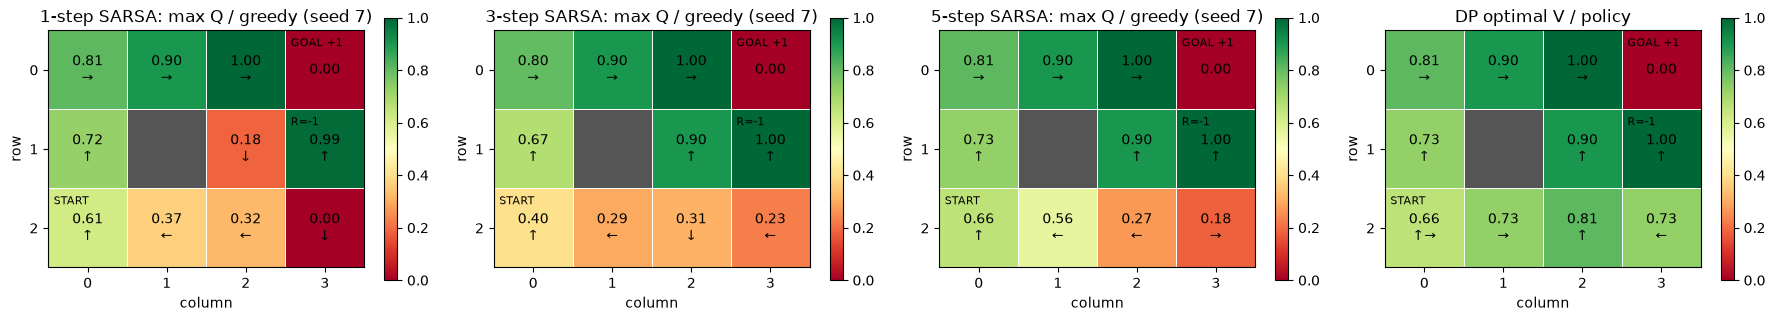

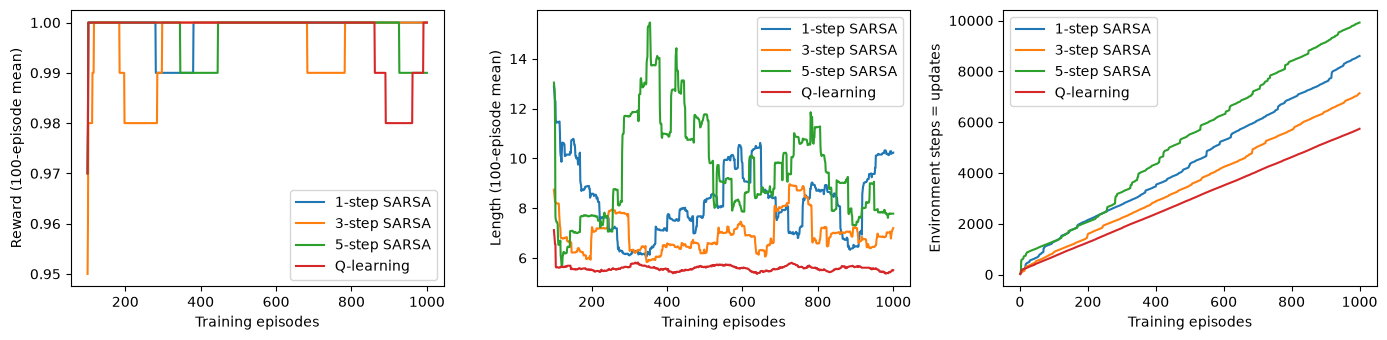

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, horizon in zip(axes[:3], (1, 3, 5)):
    q = nstep_results[7, horizon]['q_values']
    greedy = np.eye(mdp.n_actions)[q.argmax(axis=1)]
    plot_grid(q.max(axis=1), greedy, title=f'{horizon}-step SARSA: max Q / greedy (seed 7)', ax=ax)
plot_grid(control_optimal.values, control_optimal.policy, title='DP optimal V / policy', ax=axes[3])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
nstep_plot_runs = {f'{horizon}-step SARSA': nstep_results[7, horizon] for horizon in (1,3,5)}
nstep_plot_runs['Q-learning'] = expected_results[7, 'q_learning']
for label, result in nstep_plot_runs.items():
    episodes = np.arange(1, len(result['episode_lengths'])+1)
    axes[0].plot(episodes[99:], np.convolve(result['training_rewards'], np.ones(100)/100, mode='valid'), label=label)
    axes[1].plot(episodes[99:], np.convolve(result['episode_lengths'], np.ones(100)/100, mode='valid'), label=label)
    axes[2].plot(episodes, np.cumsum(result['episode_lengths']), label=label)
for ax, label in zip(axes, ('Reward (100-episode mean)', 'Length (100-episode mean)', 'Environment steps = updates')):
    ax.set(xlabel='Training episodes', ylabel=label)
    ax.legend()
plt.tight_layout(); plt.show()

### 범용성 평가와 재개 상태

이번 추가 코드는 시간 순서·owned 경험 보관·갱신 지연·종료 후 flush·실제 Bootstrap 행동 전달을 담당한다.
값 평가·행동 선택·보상 discount·테이블 갱신은 기존 Model/Estimator/Selector/TD0/UpdateRule을 사용한다.
TDN과 SequenceReplay는 구현되지 않아 재사용할 수 없었고, 현재 Replay는 Online 순서 보존에 적합하지 않았다.
새 Learner, TargetGenerator, Buffer 또는 Runner 클래스를 추가하지 않았다.

기존 SARSA Learner는 하나의 Batch와 a′를 바로 학습하며 지연 window/flush를 관리하지 않는다.
최소 공통화 후보는 현재와 같은 **ordered B=1 window, 실제 horizon, endpoint Bootstrap 값, boundary**의
명시적 입력이다. 순서·시점 관리는 n-step Q-learning/Expected SARSA에도 재사용할 수 있지만 끝점 선택은
max/기대값/실제 행동으로 다르다. Q(σ)는 중간 확률·분기 혼합이 필요해 끝점만 교체하면 완성되는 것은 아니다.
이번에는 이 인터페이스나 프레임워크 리팩터링을 추가하지 않는다.

Episode 경계의 재개는 Model.state_dict(ε 포함), n/gamma/alpha, 환경·Torch RNG를 보존한다.
도중 재개는 pending B=1 snapshots와 현재 관측·이미 선택한 행동/log_prob·환경 상태·TimeLimit 잔여 예산도 필요하다.
테스트는 고정 경험 stream 중간에서 pending/행동/RNG/Model을 복원해 같은 후속 Error/Q를 얻는지 검증한다.
현재 환경은 범용 mid-episode checkpoint API를 제공하지 않으며 수집자 책임을 숨기지 않는다.

## 15. Off-policy n-step SARSA — 고정 Target Policy 평가

Behavior Model은 데이터를 생성하고, 별도의 고정 확률표 π는 평가할 정책을 지정한다.
Q는 Qᵖⁱ를 추정하며 이 절에서는 Greedy Policy Improvement를 하지 않는다.
[Sutton & Barto §7.3, 식 (7.11)](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=171):

$$Q(S_\tau,A_\tau)\leftarrow Q(S_\tau,A_\tau)+\alpha\rho[G-Q(S_\tau,A_\tau)]$$
$$\rho=\prod_{k=\tau+1}^{\tau+m}\frac{\pi(A_k|S_k)}{b(A_k|S_k)}$$

이 식은 Bootstrap이 있는 경우다. **현재 Aτ는 제외하고 샘플한 끝점 Aτ+m은 포함한다.**
자연 종료에서는 마지막 실제 행동 A(T−1)까지만 포함한다. 빈 곱은 1이다.
Time-limit에서는 실제 마지막 관측에서 행동을 한 번 선택만 하고, 그 행동과 log b를 모든 꼬리에 재사용한다.
두 flag가 True이면 자연 종료가 우선한다. 이 Time-limit Bootstrap은 교재 자연 종료 식의 확장 규칙이다.

Transition.log_prob과 별도 끝점 log_prob은 선택 당시 값이다. 현재 Q/ε로 과거 확률을 재계산하지 않는다.
기존 TD0 역순 합성의 G와 기존 Q UpdateRule을 그대로 쓰며 `Yeff=Q+ρ(G−Q)`를 전달한다.
ρ=1은 G를 직접 전달해 On-policy 수치와 정확히 일치시키고 ρ=0은 갱신하지 않는다.
Clipping은 없다. 비유한 값/양의 비율의 수치적 underflow는 쓰기 전에 실패한다.

In [29]:
off_ns_api = runpy.run_path(str(nstep_root / 'examples' / 'gridworld_off_policy_n_step_sarsa.py'))
learn_off_ns = off_ns_api['learn_off_policy_n_step_sarsa']
compare_off_ns = off_ns_api['run_comparison']
print(inspect.getsource(learn_off_ns))

@torch.no_grad()
def learn_off_policy_n_step_sarsa(model, window, target_generator, update_rule, *,
                                target_policy, bootstrap_action=None, bootstrap_log_prob=None):
    """Update the window head; return raw/weighted errors, G, effective Y and rho.

    window contains contiguous B=1 snapshots. target_policy is a fixed floating
    (S,A) probability table owned by the caller. rho excludes the head action,
    includes subsequent executed actions and, when bootstrapping, the separately
    saved final action. Behavior logs are read from original snapshots, never
    recomputed or cast through the Q-table dtype. Logs use their recorded precision;
    summation/exp use float64. The caller removes the head only after success.

    Returned tensors have shape (1,), no graph, and table device/dtype except
    importance_ratio (float64). td_error is the actual effective-target error
    returned by the existing rule; raw_td_error is G-Q before the write. rho=1
  

### n=1/3 수치 검증과 종료 경계

A: G=2.8, ρ=2, 원래 δ=−1.2, Qnew=2.8.
B: 세 보상과 Bootstrap의 G=8.146, ρ=2×.5×3=3, Qnew=11.219.
C: 두 보상 후 자연 종료는 G=2.8, ρ=2, Qnew=2.8.
D: 두 보상 후 Truncation은 G=6.04, 끝점 비율까지 ρ=6, Qnew=14.12.
아래는 예제 함수를 호출한다. 반환 td_error는 기존 Rule이 실제로 계산한 가중 Error이고,
raw_td_error는 갱신 전 G−Q다. 둘을 같은 TD Error로 혼동하지 않는다.

In [30]:
for off_case in ('A', 'B', 'C', 'D'):
    off_rewards = [1,2,3] if off_case == 'B' else [1] if off_case == 'A' else [1,2]
    off_demo = Model(IdentityRepresentation(), TabularQEstimator(4,2)).double()
    off_pi = torch.full((4,2), .5, dtype=torch.float64)
    off_demo.estimator.q_table[0,0] = 4 if off_case == 'A' else 2
    off_demo.estimator.q_table[len(off_rewards),0] = 2 if off_case == 'A' else 4
    off_b = [.01,.25,.8] if off_case == 'B' else [.01,.25]
    if off_case == 'B':
        off_pi[2] = off_pi.new_tensor([.4,.6]); off_pi[3] = off_pi.new_tensor([.6,.4])
    if off_case == 'D':
        off_pi[2] = off_pi.new_tensor([.6,.4])
    off_window = deque(Transition(i,0,float(r),i+1,off_case=='C' and i==len(off_rewards)-1,
                                  off_case=='D' and i==len(off_rewards)-1,
                                  torch.tensor(off_b[i],dtype=torch.float64).log()).to_batch()
                       for i,r in enumerate(off_rewards))
    off_result = learn_off_ns(off_demo,off_window,TD0TargetGenerator(.9),TabularQUpdateRule(.5),
                             target_policy=off_pi,bootstrap_action=0,
                             bootstrap_log_prob=torch.tensor(.25 if off_case=='A' else .2,dtype=torch.float64).log())
    print(off_case, {key: round(value.item(),6) for key,value in off_result.items()},
          'Qnew=',round(off_demo.estimator.q_table[0,0].item(),6))
    np.testing.assert_allclose(off_demo.estimator.q_table[0,0].item(),
                               dict(A=2.8,B=11.219,C=2.8,D=14.12)[off_case],rtol=1e-6)

A {'td_error': -2.4, 'raw_td_error': -1.2, 'target': 2.8, 'effective_target': 1.6, 'importance_ratio': 2.0} Qnew= 2.8
B {'td_error': 18.438, 'raw_td_error': 6.146, 'target': 8.146, 'effective_target': 20.438, 'importance_ratio': 3.0} Qnew= 11.219
C {'td_error': 1.6, 'raw_td_error': 0.8, 'target': 2.8, 'effective_target': 3.6, 'importance_ratio': 2.0} Qnew= 2.8
D {'td_error': 24.24, 'raw_td_error': 4.04, 'target': 6.04, 'effective_target': 26.24, 'importance_ratio': 6.0} Qnew= 14.12


### 동일 경험에서 π=b와 π≠b 비교

Behavior ε=1이면 실제 확률 b(a|s)=.25다. On-policy와 Matched는 고정 Uniform π, Different는 고정 π=[.3,.2,.2,.3]을 사용한다.
같은 ε만으로 같은 정책이라 판단하지 않고, 실제로 일치하는 Uniform 확률을 사용한다.

각 Seed7/11/19에서 n=1/3/5, γ=.9, α=.05, **Notebook은 100 Episode**다.
CLI 기본 실험은 200 Episode이며 `--episodes 1000`으로 늘릴 수 있다.
Uniform Behavior 덕분에 세 모드의 실제 행동·Reward·Length·누적 Step이 동일하다.
Matched는 기존 On-policy 예제의 Q-table까지 정확히 일치해야 한다.
기준은 각각 같은 π의 policy_evaluation과 action_values로 얻은 DP Qᵖⁱ이며 최적 V*가 아니다.
RMSE는 비종료 10개 상태의 모든 행동에 대해 계산한다. 유한 표본·고정 α에서 순위나 단조 감소를 보장하지 않는다.

In [31]:
off_ns_results = []
off_ns_results.extend(compare_off_ns(seed=7, episodes=100, gamma=.9, alpha=.05, log_every=0))
print('Seed 7: exact on-policy/matched Q, rewards and lengths verified.')

Seed 7: exact on-policy/matched Q, rewards and lengths verified.


In [32]:
off_ns_results.extend(compare_off_ns(seed=11, episodes=100, gamma=.9, alpha=.05, log_every=0))
print('Seed 11: exact on-policy/matched Q, rewards and lengths verified.')

Seed 11: exact on-policy/matched Q, rewards and lengths verified.


In [33]:
off_ns_results.extend(compare_off_ns(seed=19, episodes=100, gamma=.9, alpha=.05, log_every=0))
print('Seed 19: exact on-policy/matched Q, rewards and lengths verified.')

Seed 19: exact on-policy/matched Q, rewards and lengths verified.


seed=7 n=1 mode=on_policy: steps=updates=4203 Qpi_RMSE=0.196139 rho_mean=1.000000 rho_max=1.000000 zero=0.000 ESS=4203.0
seed=7 n=1 mode=matched: steps=updates=4203 Qpi_RMSE=0.196139 rho_mean=1.000000 rho_max=1.000000 zero=0.000 ESS=4203.0
seed=7 n=1 mode=different: steps=updates=4203 Qpi_RMSE=0.195412 rho_mean=1.000999 rho_max=1.200000 zero=0.000 ESS=4045.4
seed=7 n=3 mode=on_policy: steps=updates=4203 Qpi_RMSE=0.099409 rho_mean=1.000000 rho_max=1.000000 zero=0.000 ESS=4203.0
seed=7 n=3 mode=matched: steps=updates=4203 Qpi_RMSE=0.099409 rho_mean=1.000000 rho_max=1.000000 zero=0.000 ESS=4203.0
seed=7 n=3 mode=different: steps=updates=4203 Qpi_RMSE=0.102066 rho_mean=1.004365 rho_max=1.728000 zero=0.000 ESS=3752.4
seed=7 n=5 mode=on_policy: steps=updates=4203 Qpi_RMSE=0.090768 rho_mean=1.000000 rho_max=1.000000 zero=0.000 ESS=4203.0
seed=7 n=5 mode=matched: steps=updates=4203 Qpi_RMSE=0.090768 rho_mean=1.000000 rho_max=1.000000 zero=0.000 ESS=4203.0
seed=7 n=5 mode=different: steps=updat

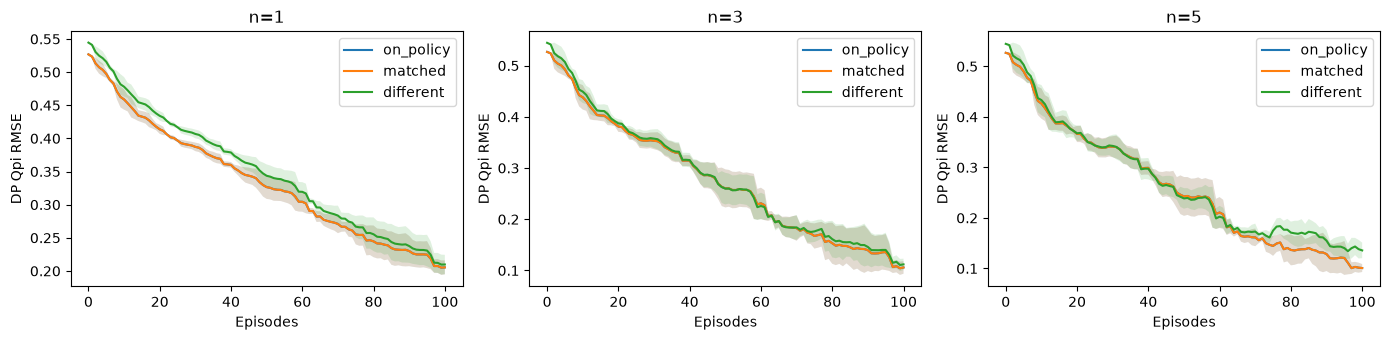

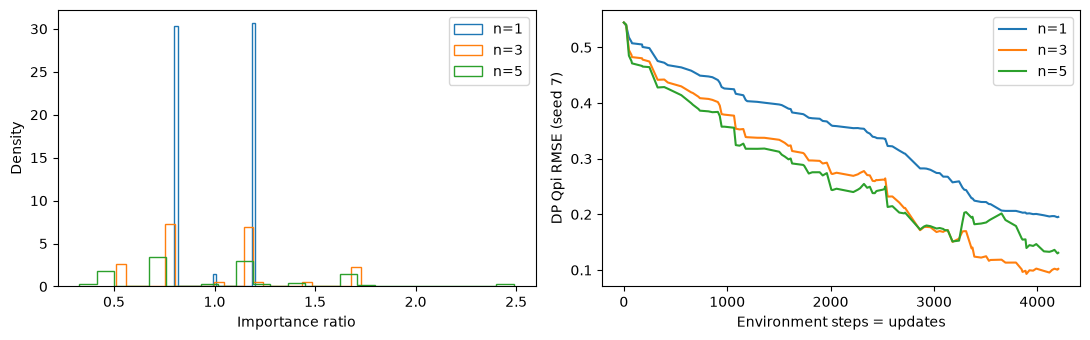

Different target pi:
 [[0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]]
Different Qpi estimate (seed19,n5):
 [[ 0.12033148  0.05276954  0.13247624  0.21223216]
 [ 0.09729261 -0.01316769  0.07155893  0.25524163]
 [ 0.30289234 -0.43402661  0.13687914  0.94046144]
 [ 0.          0.          0.          0.        ]
 [ 0.10305237 -0.10814407 -0.02332264 -0.01620547]
 [ 0.23814345 -0.35571111 -0.36540796 -1.32366615]
 [ 0.90055974 -0.51984604 -0.36855826 -1.37515342]
 [-0.01509747 -0.05747195 -0.03542446 -0.25858716]
 [-0.12316013 -0.0798452  -0.22347868 -0.2281381 ]
 [-0.31595236 -0.04529306 -0.02913171 -0.741776  ]
 [-1.1763551  -0.6607962  -0.42053649 -0.68221006]]


In [34]:
for off_run in off_ns_results:
    print(f"seed={off_run['seed']} n={off_run['n']} mode={off_run['mode']}: steps=updates={off_run['steps']} "
          f"Qpi_RMSE={off_run['q_rmse']:.6f} rho_mean={off_run['rho_mean']:.6f} "
          f"rho_max={off_run['rho_max']:.6f} zero={off_run['rho_zero_fraction']:.3f} ESS={off_run['ess']:.1f}")
for off_horizon in (1,3,5):
    for off_mode in ('on_policy','matched','different'):
        off_errors = [r['q_rmse'] for r in off_ns_results if r['n']==off_horizon and r['mode']==off_mode]
        print(f'n={off_horizon} {off_mode}: RMSE mean={np.mean(off_errors):.6f} std={np.std(off_errors):.6f}')
fig, axes = plt.subplots(1,3,figsize=(14,3.5))
for ax, off_horizon in zip(axes,(1,3,5)):
    for off_mode in ('on_policy','matched','different'):
        off_runs = [r for r in off_ns_results if r['n']==off_horizon and r['mode']==off_mode]
        curves = np.array([[h['q_rmse'] for h in r['history']] for r in off_runs])
        x = [h['episodes'] for h in off_runs[0]['history']]
        avg, spread = curves.mean(0),curves.std(0)
        ax.plot(x,avg,label=off_mode); ax.fill_between(x,avg-spread,avg+spread,alpha=.15)
    ax.set(title=f'n={off_horizon}',xlabel='Episodes',ylabel='DP Qpi RMSE'); ax.legend()
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
for off_horizon in (1,3,5):
    off_run = next(r for r in off_ns_results if r['seed']==7 and r['n']==off_horizon and r['mode']=='different')
    axes[0].hist(off_run['importance_ratios'],bins=25,histtype='step',density=True,label=f'n={off_horizon}')
    axes[1].plot([h['steps'] for h in off_run['history']],[h['q_rmse'] for h in off_run['history']],label=f'n={off_horizon}')
axes[0].set(xlabel='Importance ratio',ylabel='Density'); axes[0].legend()
axes[1].set(xlabel='Environment steps = updates',ylabel='DP Qpi RMSE (seed 7)'); axes[1].legend()
plt.tight_layout(); plt.show()
print('Different target pi:\n',off_ns_results[-1]['target_policy'])
print('Different Qpi estimate (seed19,n5):\n',off_ns_results[-1]['q_values'])

### 재사용성, Coverage, Checkpoint와 Control 확장

Model/TabularQ/Selector, Transition/Batch, TD0와 Q Rule은 변경하지 않았다.
원래 n-step 예제의 Window/Index 검증과 On-policy 비교 run을 재사용했다.
기존 run_episode에는 끝점 log_prob을 전달하는 확장 경로가 없어 짧은 deque 수집·flush 부분은 새 예제에도 남아 있다.
기존 셀의 inspect 출력을 보존하기 위해 그 함수와 라이브러리의 공개 API는 수정하지 않았다.

Coverage π>0 ⇒ b>0는 수집자의 책임이다. 선택 행동의 log_prob만으로 미관측 행동의 Support는 검증할 수 없다.
Transition.log_prob은 실행한 행동을 표현한다. 아직 실행하지 않은 끝점 행동과 확률은 별도로 보관한다.

재개에는 Model.state_dict, 고정 π, n/γ/α, pending, 선택한 행동/log_prob, Torch RNG,
환경 상태/RNG/TimeLimit 잔여 예산과 누적 통계가 필요하다. 테스트는 고정 stream에서 Model/Window/끝점/RNG를 복원한다.
환경의 중간 저장 API나 Runner는 추가하지 않았다.

최소 공통화 후보는 ordered Window, 경계, 실제 Horizon, sampled endpoint와 sampling-time log b를 전달하는 함수다.
Expected SARSA는 끝점 기대값을 사용하므로 끝점 IS 인자를 제외한다. Tree Backup은 분기 기대값,
Q(σ)는 중간 확률과 σ도 필요하다. 끝점 교체만으로 모든 알고리즘을 표현할 수 있다고 주장하지 않는다.
향후 Control은 정책 평가 검증을 바탕으로 Q에 따라 π를 개선하는 규칙을 별도로 두는 설계가 가능하다.
이번 Target Policy는 고정이며 Control은 구현하지 않았다.

## 16. Online n-step Tree Backup — 샘플 분기와 기대값의 재귀 합성

[Sutton & Barto §7.5, 식 (7.15–16)](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=175).
실제 행동의 분기는 다음 Return으로 확장하고 다른 행동은 현재 Q로 평가한다.

$$G_k=R_{k+1}+\gamma\left[\sum_{a\ne A_{k+1}}\pi(a|S_{k+1})Q(S_{k+1},a)
+\pi(A_{k+1}|S_{k+1})G_{k+1}\right]$$

마지막 Bootstrap은 $V_\pi(S)=\sum_a\pi(a|S)Q(S,a)$다. 중간 continuation은
$C=V_\pi+\pi(A_{next}|S_{next})(G-Q(S_{next},A_{next}))$로 표현한다.
기존 TD0.generate가 `R + gamma*C`를 수행하고 기존 Q Rule이 signed Error로 갱신한다.
Tree Backup은 π/b, Behavior 확률에 의한 가중치, Effective Target을 사용하지 않는다.

하나의 호출은 필요한 다음 상태들의 Q와 π를 한 번에 평가하고 그 Snapshot에서 재귀한다.
고정 확률 Tensor 또는 기존 Selector.probabilities(estimate)를 Target Policy로 전달할 수 있다.
Model/Estimator/Selector/Transition/TD0/UpdateRule은 그대로 유지하고 새 Learner는 추가하지 않는다.

In [35]:
tree_api = runpy.run_path(str(nstep_root / 'examples' / 'gridworld_tree_backup.py'))
learn_tree = tree_api['learn_tree_backup']
compare_tree = tree_api['run_comparison']
print(inspect.getsource(learn_tree))

@torch.no_grad()
def learn_tree_backup(model, window, target_generator, update_rule, *, target_policy):
    """Update the oldest row of a contiguous, ordered B=1 window.

    target_policy is a caller-owned fixed floating probability Tensor (S,A),
    or an existing discrete Selector with probabilities(estimate). Fixed rows
    are explicitly cast to Q dtype; device must match. A single Model estimate
    supplies all needed next-state Q rows and dynamic policy probabilities before
    any writes. The natural terminal endpoint is excluded from that estimate.

    Intermediate actions come from the following window row. The final bootstrap
    is an expectation, so no endpoint action, behavior probability or importance
    ratio is used. pi=0 cuts only the sampled branch; pi=1 carries G directly.
    Each TD0 call performs one reward backup. Return the existing rule's signed
    error (1,), in table dtype/device with no graph. The caller pops after success.
    Separate flush calls re-e

### n=1/3의 수치 검증과 짧은 경계

A: Q(S1)=[10,2], π=[.25,.75]의 기대값은 4, G=4.6, Error=2.6, Qnew=3.3.
B: 실제 A1=0, A2=1에서 역순 G는 6.6 → 6.536 → 3.8206, Qnew=2.9103.
C: 두 보상 후 자연 종료의 head Target은 2.8, 마지막 Target은 2.
D: 두 보상 후 Truncation의 head Target은 3.61, 마지막 Target은 5.6, 첫 Qnew=2.805.
아래는 동일 예제 함수를 호출한다. 수식 구현을 Notebook에 복제하지 않는다.

In [36]:
for tree_case in ('A','B','C','D'):
    tree_rewards = [1,2,3] if tree_case=='B' else [1] if tree_case=='A' else [1,2]
    tree_actions = [0,0,1] if tree_case=='B' else [0]*len(tree_rewards)
    tree_demo = Model(IdentityRepresentation(),TabularQEstimator(4,2)).double()
    tree_pi = torch.full((4,2),.5,dtype=torch.float64)
    tree_demo.estimator.q_table[0,0] = 2
    tree_demo.estimator.q_table[1] = tree_pi.new_tensor([10.,2.]); tree_pi[1] = tree_pi.new_tensor([.25,.75])
    tree_demo.estimator.q_table[2] = tree_pi.new_tensor([4.,8.]); tree_pi[2] = tree_pi.new_tensor([.6,.4])
    tree_demo.estimator.q_table[3] = tree_pi.new_tensor([6.,2.])
    if tree_case in ('C','D'):
        tree_demo.estimator.q_table[2] = tree_pi.new_tensor([6.,2.]); tree_pi[2] = .5
    tree_pending = deque(Transition(i,a,float(r),i+1,tree_case=='C' and i==len(tree_rewards)-1,
                                    tree_case=='D' and i==len(tree_rewards)-1).to_batch()
                         for i,(r,a) in enumerate(zip(tree_rewards,tree_actions)))
    tree_error = learn_tree(tree_demo,tree_pending,TD0TargetGenerator(.9),TabularQUpdateRule(.5),target_policy=tree_pi)
    tree_g = 2 + tree_error.item()
    print(tree_case,'Target=',round(tree_g,6),'Error=',round(tree_error.item(),6),
          'Qnew=',round(tree_demo.estimator.q_table[0,0].item(),6))
    np.testing.assert_allclose(tree_g,dict(A=4.6,B=3.8206,C=2.8,D=3.61)[tree_case],rtol=1e-12)
    if tree_case in ('C','D'):
        tree_pending.popleft()
        tail_error = learn_tree(tree_demo,tree_pending,TD0TargetGenerator(.9),TabularQUpdateRule(.5),target_policy=tree_pi)
        print('  tail Target=',round(10+tail_error.item(),6))
        np.testing.assert_allclose(10+tail_error.item(),2 if tree_case=='C' else 5.6,rtol=1e-12)

A Target= 4.6 Error= 2.6 Qnew= 3.3
B Target= 3.8206 Error= 1.8206 Qnew= 2.9103
C Target= 2.8 Error= 0.8 Qnew= 2.4
  tail Target= 2.0
D Target= 3.61 Error= 1.61 Qnew= 2.805
  tail Target= 5.6


### n=1 Expected SARSA 동등성과 정책 분기

n=1은 중간 분기 없이 마지막 ΣπQ만 사용하므로 Expected SARSA와 같다.
동적 Target으로 `model.action_selector`를 넘기면 같은 estimate에서 probabilities를 조회한다.
단위 테스트는 float32/64와 종료/Truncation/동시 flag에서 행동·보상·Target·Error·Q·RNG까지 정확히 비교한다.

중간 π=0은 그 재귀 분기만 끊는다. 다른 행동의 기대값은 남으며 전체 갱신을 버리지 않는다.
π=1은 G를 직접 전달해 불필요한 상쇄를 피한다. 결정적 정책을 실제 경로가 따르는 경우
Sampled n-step SARSA Return과 같다. 일반 확률적 정책에서는 두 Return이 달라질 수 있다.

Online 순서는 step → Transition snapshot → 가능한 head 갱신 → 다음 행동 선택이다.
자연 종료는 마지막 Q를 평가하지 않는다. Time-limit은 마지막 관측의 기대값으로 Bootstrap하며
끝점 행동을 선택하지 않는다. 잔여 head는 step/act 없이 한 번씩 처리하고 각 호출은 최신 Q를 읽는다.

In [37]:
tree_dynamic = Model(IdentityRepresentation(),TabularQEstimator(4,2),EpsilonGreedyActionSelector(0.)).double()
tree_dynamic.estimator.q_table[1] = torch.tensor([4.,4.],dtype=torch.float64)
tree_dynamic_batch = Transition(0,0,1.,1,False,False).to_batch()
tree_rng_before = torch.get_rng_state().clone()
tree_dynamic_error = learn_tree(tree_dynamic,deque([tree_dynamic_batch]),TD0TargetGenerator(.9),
                                TabularQUpdateRule(.5),target_policy=tree_dynamic.action_selector)
assert torch.equal(tree_rng_before,torch.get_rng_state())
print('Dynamic tied-policy Expected SARSA target=',tree_dynamic_error.item(),'RNG unchanged')
np.testing.assert_allclose(tree_dynamic_error.item(),4.6,rtol=1e-12)

Dynamic tied-policy Expected SARSA target= 4.6 RNG unchanged


### 같은 정책의 DP Qπ로 비교: Seeds7/11/19, n=1/3/5

각 run은 200 Episode, γ=.9, α=.05, Uniform Behavior(ε=1)다.
고정 Target은 Uniform(π=b) 또는 [.3,.2,.2,.3](π≠b)이며 Q를 갱신해도 변하지 않는다.
기존 On-policy 기준 및 Off-policy n-step SARSA의 matched/different 실험 함수를 재사용한다.
각 정책의 DP policy_evaluation/action_values로 계산한 Qπ에 대해 비종료 10개 상태·모든 행동의 RMSE를 기록한다.

아래 호출은 n·Seed별로 구분해 긴 실험도 셀별로 진행 상태를 확인할 수 있게 한다.
같은 Uniform Behavior와 자연 종료 경험은 모두 일치한다. SARSA는 Time-limit에서 끝점 행동을 추가로
선택하지만 Tree Backup은 선택하지 않으므로 Truncation 이후의 RNG와 경험까지 같다고 가정하지 않는다.
Tree Backup에 Importance Weight나 ESS는 계산하지 않는다. 방법 간 성능 순위를 통과 조건으로 삼지 않는다.

In [38]:
tree_results = []
tree_results.extend(compare_tree(seed=7,episodes=200,ns=(1,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=7, n=1, five comparison runs, 200 episodes each.')

Completed: seed=7, n=1, five comparison runs, 200 episodes each.


In [39]:
tree_results.extend(compare_tree(seed=7,episodes=200,ns=(3,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=7, n=3, five comparison runs, 200 episodes each.')

Completed: seed=7, n=3, five comparison runs, 200 episodes each.


In [40]:
tree_results.extend(compare_tree(seed=7,episodes=200,ns=(5,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=7, n=5, five comparison runs, 200 episodes each.')

Completed: seed=7, n=5, five comparison runs, 200 episodes each.


In [41]:
tree_results.extend(compare_tree(seed=11,episodes=200,ns=(1,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=11, n=1, five comparison runs, 200 episodes each.')

Completed: seed=11, n=1, five comparison runs, 200 episodes each.


In [42]:
tree_results.extend(compare_tree(seed=11,episodes=200,ns=(3,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=11, n=3, five comparison runs, 200 episodes each.')

Completed: seed=11, n=3, five comparison runs, 200 episodes each.


In [43]:
tree_results.extend(compare_tree(seed=11,episodes=200,ns=(5,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=11, n=5, five comparison runs, 200 episodes each.')

Completed: seed=11, n=5, five comparison runs, 200 episodes each.


In [44]:
tree_results.extend(compare_tree(seed=19,episodes=200,ns=(1,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=19, n=1, five comparison runs, 200 episodes each.')

Completed: seed=19, n=1, five comparison runs, 200 episodes each.


In [45]:
tree_results.extend(compare_tree(seed=19,episodes=200,ns=(3,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=19, n=3, five comparison runs, 200 episodes each.')

Completed: seed=19, n=3, five comparison runs, 200 episodes each.


In [46]:
tree_results.extend(compare_tree(seed=19,episodes=200,ns=(5,),gamma=.9,alpha=.05,log_every=0))
print('Completed: seed=19, n=5, five comparison runs, 200 episodes each.')

Completed: seed=19, n=5, five comparison runs, 200 episodes each.


seed=7 n=1 on_policy_sarsa matched: steps=updates=8419 reward(last100)=-1.230 length(last100)=42.16 terminal=200 truncated=0 Qpi_RMSE=0.074577
seed=7 n=1 off_policy_sarsa matched: steps=updates=8419 reward(last100)=-1.230 length(last100)=42.16 terminal=200 truncated=0 Qpi_RMSE=0.074577
seed=7 n=1 off_policy_sarsa different: steps=updates=8419 reward(last100)=-1.230 length(last100)=42.16 terminal=200 truncated=0 Qpi_RMSE=0.071736
seed=7 n=1 tree_backup matched: steps=updates=8419 reward(last100)=-1.230 length(last100)=42.16 terminal=200 truncated=0 Qpi_RMSE=0.097615
seed=7 n=1 tree_backup different: steps=updates=8419 reward(last100)=-1.230 length(last100)=42.16 terminal=200 truncated=0 Qpi_RMSE=0.088023
seed=7 n=3 on_policy_sarsa matched: steps=updates=8419 reward(last100)=-1.230 length(last100)=42.16 terminal=200 truncated=0 Qpi_RMSE=0.113803
seed=7 n=3 off_policy_sarsa matched: steps=updates=8419 reward(last100)=-1.230 length(last100)=42.16 terminal=200 truncated=0 Qpi_RMSE=0.113803


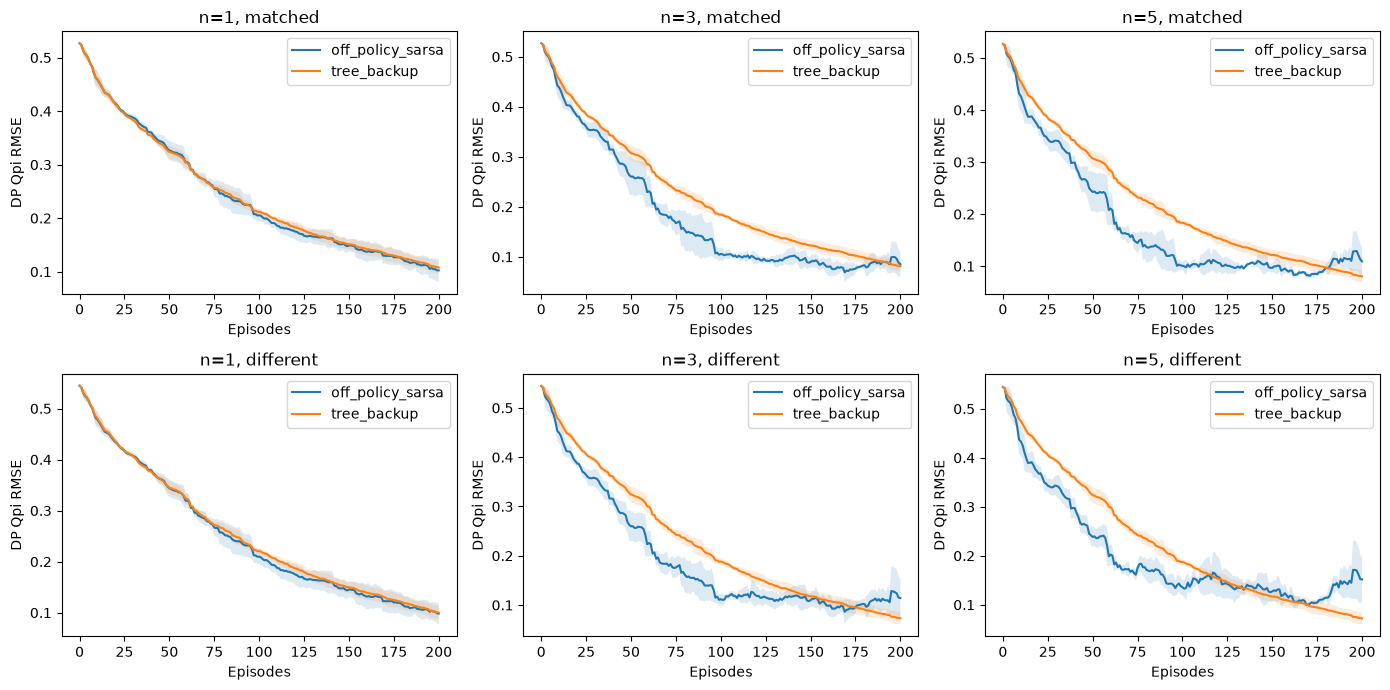

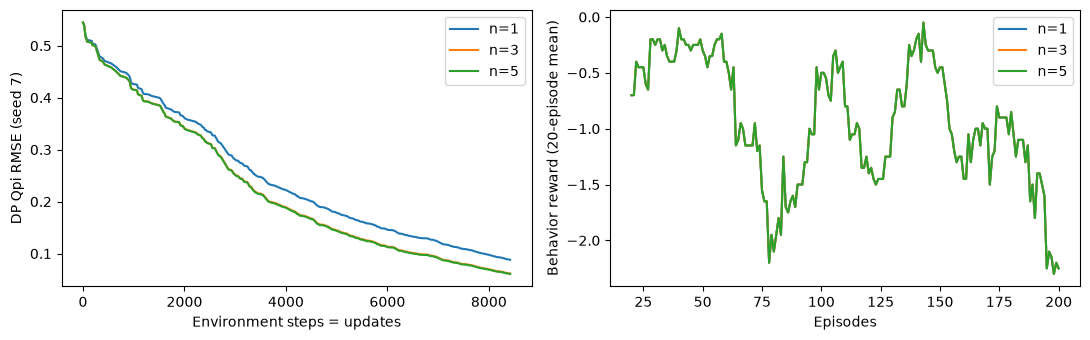

Tree target pi:
 [[0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]]
Tree Qpi (seed19,n5):
 [[ 0.09517666  0.02651071  0.09508617  0.18425699]
 [ 0.18005353  0.18175795  0.09245092  0.32751139]
 [ 0.31813029 -0.32138524  0.17012057  0.99645516]
 [ 0.          0.          0.          0.        ]
 [ 0.09573102 -0.06160124  0.02663077  0.02646837]
 [ 0.32354095 -0.31553762 -0.3243952  -1.18192903]
 [ 0.99011164 -0.56727077 -0.31767793 -1.16828433]
 [ 0.0266464  -0.062584   -0.06292149 -0.18098731]
 [-0.18000348 -0.17788238 -0.06194522 -0.34421614]
 [-0.33811626 -0.33479927 -0.17119739 -0.62879774]
 [-1.19071414 -0.60262609 -0.31925744 -0.60669042]]


In [47]:
for tree_run in tree_results:
    print(f"seed={tree_run['seed']} n={tree_run['n']} {tree_run['algorithm']} {tree_run['target_mode']}: "
          f"steps=updates={tree_run['steps']} reward(last100)={np.mean(tree_run['training_rewards'][-100:]):.3f} "
          f"length(last100)={np.mean(tree_run['episode_lengths'][-100:]):.2f} "
          f"terminal={tree_run['terminated_episodes']} truncated={tree_run['truncated_episodes']} Qpi_RMSE={tree_run['q_rmse']:.6f}")
for tree_n in (1,3,5):
    for tree_mode in ('matched','different'):
        for tree_algorithm in ('off_policy_sarsa','tree_backup'):
            tree_errors = [r['q_rmse'] for r in tree_results if r['n']==tree_n and r['target_mode']==tree_mode and r['algorithm']==tree_algorithm]
            print(f'n={tree_n} {tree_algorithm} {tree_mode}: RMSE mean={np.mean(tree_errors):.6f} std={np.std(tree_errors):.6f}')
fig,axes = plt.subplots(2,3,figsize=(14,7))
for row,tree_mode in enumerate(('matched','different')):
    for col,tree_n in enumerate((1,3,5)):
        ax = axes[row,col]
        for tree_algorithm in ('off_policy_sarsa','tree_backup'):
            tree_runs = [r for r in tree_results if r['n']==tree_n and r['target_mode']==tree_mode and r['algorithm']==tree_algorithm]
            curves = np.array([[h['q_rmse'] for h in r['history']] for r in tree_runs])
            x = [h['episodes'] for h in tree_runs[0]['history']]
            avg,spread = curves.mean(0),curves.std(0)
            ax.plot(x,avg,label=tree_algorithm);ax.fill_between(x,avg-spread,avg+spread,alpha=.15)
        ax.set(title=f'n={tree_n}, {tree_mode}',xlabel='Episodes',ylabel='DP Qpi RMSE');ax.legend()
plt.tight_layout();plt.show()
fig,axes = plt.subplots(1,2,figsize=(11,3.5))
for tree_n in (1,3,5):
    tree_run = next(r for r in tree_results if r['seed']==7 and r['n']==tree_n and r['target_mode']=='different' and r['algorithm']=='tree_backup')
    axes[0].plot([h['steps'] for h in tree_run['history']],[h['q_rmse'] for h in tree_run['history']],label=f'n={tree_n}')
    axes[1].plot(np.arange(20,201),np.convolve(tree_run['training_rewards'],np.ones(20)/20,mode='valid'),label=f'n={tree_n}')
axes[0].set(xlabel='Environment steps = updates',ylabel='DP Qpi RMSE (seed 7)');axes[0].legend()
axes[1].set(xlabel='Episodes',ylabel='Behavior reward (20-episode mean)');axes[1].legend()
plt.tight_layout();plt.show()
print('Tree target pi:\n',tree_results[-1]['target_policy'])
print('Tree Qpi (seed19,n5):\n',tree_results[-1]['q_values'])

### 컴포넌트 재사용과 남은 조합 인터페이스

Model/TabularQ/Selector/Transition/TD0/Q Rule은 수정하지 않았다.
Window 검증과 기존 비교 실험을 재사용하고, 중간 실제 행동·π/Q·재귀 continuation은 예제 함수에서 명시한다.
SARSA의 수집 함수는 다음 행동을 갱신 전에 선택하므로 Tree Backup의 step→update→act 순서를 공유할 수 없다.
현재 Learner는 한 Batch의 max/gather Bootstrap을 고정한다. 재귀 Return과 시간 관리는 예제 수준에 남아 있다.

최소 공통화 후보는 ordered Window, 실제 horizon/boundary와 같은 Snapshot의 Q/π 및 sampled 중간 행동을
전달하는 작은 계산 함수다. endpoint callback만으로 Tree Backup 전체를 표현할 수는 없다.
Q(σ)는 시점별 σ, sampled/expected 혼합, 필요한 행동·Target 확률, Off-policy 보정의 책임까지 명시해야 한다.
이번에는 공통 Base/새 Policy/Runner나 Q(σ)를 구현하지 않았다.

재개에는 Model.state_dict, Target Policy(동적 Selector는 구조·ε 상태), pending, 현재 선택 행동/log_prob,
n/γ/α, Torch RNG 및 환경 위치/RNG/TimeLimit 잔여 예산을 함께 저장한다.
테스트는 고정 stream의 Model/정책/Window/선택 행동/RNG 복원 후 후속 학습과 다음 행동이 일치하는지 확인한다.
Tree Backup 계산은 Behavior log_prob을 읽거나 그 값으로 Target을 가중하지 않는다.

## 17. n-step Q(σ) — Control Variate와 기본 컴포넌트의 조합

[Sutton & Barto 2판 §7.6, 식 (7.17)](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=177)의 **본문 수학적 정의**를 사용한다.

$$\bar V(S_k)=\sum_a\pi(a|S_k)Q(S_k,a),\qquad
\rho_k=\frac{\pi(A_k|S_k)}{b(A_k|S_k)},\qquad
c_k=\sigma_k\rho_k+(1-\sigma_k)\pi(A_k|S_k)$$
$$G_{j:h}=R_{j+1}+\gamma[\bar V(S_{j+1})+c_{j+1}(G_{j+1:h}-Q(S_{j+1},A_{j+1}))]$$

σ=0은 Tree Backup, σ=1은 Control Variate를 포함한 Return이다. 기존 Sampled SARSA Target과
최종 선형보간하지 않는다. 한 호출 안의 Q·π는 갱신 전 같은 Snapshot이며, TD0TargetGenerator를
각 보상 Backup에 쓰고 TabularQUpdateRule로 head 한 행을 갱신한다. 신규 Learner는 없다.

**본문/의사코드의 불일치:** 156쪽 본문은 비종료 Horizon에서 $G_{h:h}=Q(S_h,A_h)$지만
같은 페이지 의사코드는 `G=0`으로 시작한다. 이들은 다른 수치를 만든다. 본문의 경계 조건을
선택하므로 마지막 residual은 0이고 $G_{h-1:h}=R_h+\gamma\bar V(S_h)$로 시작한다.
끝점 행동·log b·σ_h를 요구하지 않는다. 자연 종료는 $G_{T-1:T}=R_T$다.
Time-limit은 실제 마지막 관측의 기대값을 사용하고 flush 중 행동을 추가로 선택하지 않는다.
이 불일치를 공식적으로 인정된 오류라고 단정하지 않는다. 공식 정오표 확인은 완료하지 못했다.

본문의 업데이트 설명은 (7.11)을 참조하지만 그 식의 전체 IS 비율을 다시 곱하면 여기서 선택한
(7.17)의 per-decision 보정과 중복된다. 같은 페이지 상자의 직접 `Q += α(G-Q)`와 사용자가
확정한 계약대로 별도의 전체 비율을 곱하지 않는다. 구현과 경계 선택을 명시적으로 구분한다.

In [48]:
# examples는 설치 패키지가 아니다. 표준 namespace package를 한 번 지정한다.
# sys.path는 변경하지 않고, 새 runpy 의존성 체인은 만들지 않는다.
import importlib.machinery
import importlib.util
import sys
if 'examples' not in sys.modules:
    qs_spec = importlib.machinery.ModuleSpec('examples', loader=None, is_package=True)
    qs_spec.submodule_search_locations = [str(nstep_root / 'examples')]
    sys.modules['examples'] = importlib.util.module_from_spec(qs_spec)
from examples import gridworld_q_sigma as qs
print(inspect.getsource(qs.learn_q_sigma))

@torch.no_grad()
def learn_q_sigma(model, window, target_generator, update_rule, *, target_policy, sigma):
    """Compute Eq. 7.17 from one Q/pi snapshot, then update only the window head.

    window contains contiguous owned B=1 TransitionBatch records. sigma is a
    fixed scalar or m frozen values [sigma_(t+1), ..., sigma_(t+m)], where m is
    len(window). The last value is a validated placeholder: the horizon residual
    G_h:h-Q(S_h,A_h) is zero. No endpoint action/log is required or sampled.
    Callbacks belong to collection, never this function. Intermediate b comes
    from original sampling-time log_prob, before batch floating-dtype conversion.

    target_policy is a fixed (S,A) Tensor or existing discrete Selector. Q and
    dynamic pi share one estimate before any write. Natural termination starts
    at the last reward; truncation uses the final observation's expected Q.
    Each reward backup reuses TD0TargetGenerator. There is no second IS product.
    Numeric failure

### n=3의 σ 시점과 Horizon 경계

Rewards=[1,2,3], γ=.9, α=.5, Q(S0,A0)=2.
S1: Q=[10,2], π=[.25,.75], 실제 A1=0, b=.5, σ1=.5.
S2: Q=[4,8], π=[.6,.4], 실제 A2=1, b=.25, σ2=.25.
S3: Q=[6,2], π=[.5,.5]. σ3=.75는 마지막 residual=0이라 사용하지 않는다.
ρ1=.5, ρ2=1.6, c1=.375, c2=.7.
역순 Return=6.6 → 6.158 → **3.303325**, Qnew=**2.6516625**.

`learn_q_sigma(..., sigma=[σ_(t+1),…,σ_h])`는 이미 결정된 값을 받는다.
현재 head 행동의 σ·ρ는 적용하지 않는다. Callback은 수집 시 한 번 호출해 별도의 aligned deque에
보존한다. 행동의 log b는 기존 TransitionBatch에 저장한다. 예제 함수를 호출하며 수식을 재구현하지 않는다.

In [49]:
qs_demo = Model(IdentityRepresentation(), TabularQEstimator(4,2)).double()
qs_demo.estimator.q_table.copy_(torch.tensor([[2.,0.],[10.,2.],[4.,8.],[6.,2.]],dtype=torch.float64))
qs_pi = torch.tensor([[.5,.5],[.25,.75],[.6,.4],[.5,.5]],dtype=torch.float64)
qs_original = {key:value.clone() for key,value in qs_demo.state_dict().items()}
qs_window = deque(Transition(i,a,float(r),i+1,False,False,torch.tensor(b,dtype=torch.float64).log()).to_batch()
                  for i,(r,a,b) in enumerate(zip([1,2,3],[0,0,1],[.5,.5,.25])))
for qs_endpoint_sigma in (0.,.75,1.):
    qs_demo.load_state_dict(qs_original)
    qs_rng = torch.get_rng_state().clone()
    qs_result = qs.learn_q_sigma(qs_demo,qs_window,TD0TargetGenerator(.9),TabularQUpdateRule(.5),
                                target_policy=qs_pi,sigma=[.5,.25,qs_endpoint_sigma])
    assert torch.equal(qs_rng,torch.get_rng_state())
    np.testing.assert_allclose(qs_result['target'].item(),3.303325,rtol=1e-12)
    np.testing.assert_allclose(qs_demo.estimator.q_table[0,0].item(),2.6516625,rtol=1e-12)
    print('sigma_h=',qs_endpoint_sigma,'target=',round(qs_result['target'].item(),8),
          'Qnew=',round(qs_demo.estimator.q_table[0,0].item(),8),
          'rho=',qs_result['importance_ratios'].tolist(),'c=',qs_result['coefficients'].tolist())

sigma_h= 0.0 target= 3.303325 Qnew= 2.6516625 rho= [0.5, 1.6] c= [0.375, 0.7000000000000001]
sigma_h= 0.75 target= 3.303325 Qnew= 2.6516625 rho= [0.5, 1.6] c= [0.375, 0.7000000000000001]
sigma_h= 1.0 target= 3.303325 Qnew= 2.6516625 rho= [0.5, 1.6] c= [0.375, 0.7000000000000001]


### σ=0 / σ=1의 정확한 관계

n=1 비종료 Target은 모든 σ에서 **4.6**이다. σ=0은 동일 Snapshot·dtype·Window·경계의
Tree Backup과 bit-exact하다. σ=1은 sampled Return에 Control Variate를 더한 교재 정의다.
π=b라도 일반적인 확률적 정책에서는 $\bar V-Q(S,A)$가 표본마다 0은 아니다.
결정적인 π=b가 실제 경로를 따르거나 관련 Q가 행동에 무관한 경우 등에서는 Sampled Return과 같다.

위 n=3 Window에서 σ=1 Target은 2.3608, Sampled SARSA(A3=0)는 9.604이다.
π≠b에서 중간 ρ와 Control Variate가 함께 작용한다. σ=.5 Target은 3.17575이며
σ=0/1의 Target 평균 3.0907과 다르다. 단순 최종 보간으로 구현하지 않는다.

다른 On-policy 표현인 [De Asis 외, AAAI 2018 식 (13–14)](https://cdn.aaai.org/ojs/11631/11631-13-15159-1-2-20201228.pdf#page=4)는
`R + gamma*[sigma*Q(sampled)+(1-sigma)*Vbar] - Q(current)`의 TD Error를 쓴다.
이 표현의 끝점 혼합과 Control Variate가 포함된 이번 본문 정의를 구분한다. 같은 Snapshot에서
본문 continuation에는 추가 `sigma*(Vbar-Q(sampled))` 보정항이 있다. 대체 모드를 구현하거나
그 논문의 Off-policy 보정식을 이번 식 (7.17)에 함께 적용하지 않는다.

In [50]:
for qs_sigma in (0.,.5,1.):
    qs_demo.load_state_dict(qs_original)
    qs_single = qs.learn_q_sigma(qs_demo,deque([qs_window[0]]),TD0TargetGenerator(.9),
                                  TabularQUpdateRule(.5),target_policy=qs_pi,sigma=qs_sigma)
    np.testing.assert_allclose(qs_single['target'].item(),4.6,rtol=1e-12)
    qs_demo.load_state_dict(qs_original)
    qs_multi = qs.learn_q_sigma(qs_demo,qs_window,TD0TargetGenerator(.9),
                                TabularQUpdateRule(.5),target_policy=qs_pi,sigma=qs_sigma)
    print('sigma=',qs_sigma,'n1 Target=',round(qs_single['target'].item(),8),
          'n3 Target=',round(qs_multi['target'].item(),8))
qs_demo.load_state_dict(qs_original)
qs_sarsa_error = qs.sampled.learn_n_step_sarsa(qs_demo,qs_window,TD0TargetGenerator(.9),
                                              TabularQUpdateRule(.5),next_action=0)
print('Sampled SARSA n3 Target=',round(2+qs_sarsa_error.item(),8))
np.testing.assert_allclose(2+qs_sarsa_error.item(),9.604,rtol=1e-12)

sigma= 0.0 n1 Target= 4.6 n3 Target= 3.8206
sigma= 0.5 n1 Target= 4.6 n3 Target= 3.17575
sigma= 1.0 n1 Target= 4.6 n3 Target= 2.3608
Sampled SARSA n3 Target= 9.604


### Online 수집과 동적 σ의 보관

`run_episode`は reset/stepを直接実行する。n個集まれば最古のheadを学習してpopし、その後に
次の実行行動を選ぶ。σ providerもその選択時に一度だけ呼ぶ。両方のdequeを同時にpopする。
`terminated`優先、`truncated-only`は期待値Bootstrap、残りは新たなstep/act/providerなしでflushする。
以下の2-step time-limitでも学習回数=実Step数。これは環境モデルを所有するRunnerではない。

In [51]:
qs_provider_calls = []
def qs_sigma_provider(state,action,timestep):
    qs_provider_calls.append((state,action,timestep))
    return .25 if timestep%2==0 else .75
qs_online_model = Model(IdentityRepresentation(),TabularQEstimator(len(DLFS4_STATES),4),
                         EpsilonGreedyActionSelector(1.)).double()
qs_env = make_dlfs4_gridworld_env(max_episode_steps=2)
torch.manual_seed(7)
try:
    qs_online = qs.run_episode(qs_env,qs_online_model,TD0TargetGenerator(.9),TabularQUpdateRule(.05),
                               target_policy=torch.full_like(qs_online_model.estimator.q_table,.25),
                               sigma=qs_sigma_provider,n=3,seed=7)
finally:
    qs_env.close()
assert qs_online['truncated'] and len(qs_provider_calls)==qs_online['steps']==qs_online['updates']==2
print('steps=updates=',qs_online['steps'],'provider calls=',qs_provider_calls,
      'stored sigma=',qs_online['sigmas'].tolist(),'truncated=',qs_online['truncated'])

steps=updates= 2 provider calls= [(7, 1, 0), (7, 2, 1)] stored sigma= [0.25, 0.75] truncated= True


### 고정 π의 DP Qπ 비교: σ=0/.25/.5/.75/1과 시간 패턴

이 Notebook은 n=3, Seeds7/11/19, 각 200 Episode, γ=.9, α=.05를 사용한다.
Behavior는 Uniform(ε=1), Target은 Uniform(π=b) 또는 [.3,.2,.2,.3](π≠b)다.
이미 실행한 §16의 SARSA/Tree Backup 결과를 재사용하고 설정 일치를 확인한다.
CLI는 n=1/3/5에서도 동일하게 비교한다. 시간 패턴 [0,1]은 각 Episode의 실행 시각에서 반복한다.

RMSE는 각 Target의 DP Qπ와 비종료 10개 상태×모든 4행동으로 계산한다.
Uniform Behavior이므로 모든 방법의 Reward/Length/Step은 같고 σ=0과 Tree의 Q도 일치한다.
Truncation에서 SARSA는 추가 끝점 행동을 선택하므로 모든 방법의 RNG 일치를 일반화하지 않는다.
그림의 음영은 Seed 간 표준편차이며, 단일 Seed의 성능 순위를 성공 조건으로 삼지 않는다.

In [52]:
qs_results = []
qs_sigmas = (0.,.25,.5,.75,1.,(0.,1.))

In [53]:
qs_refs = [r for r in tree_results if r['seed']==7 and r['n']==3]
qs_group = qs.run_comparison(seed=7,episodes=200,ns=(3,),sigmas=(),reference_results=qs_refs,log_every=0)
for qs_sigma in qs_sigmas:
    _,qs_run = qs.train_and_evaluate(target_mode='matched',n=3,sigma=qs_sigma,episodes=200,seed=7,log_every=0)
    qs_tree_ref = next(r for r in qs_group if r['algorithm']=='tree_backup' and r['target_mode']=='matched')
    for qs_key in ('training_rewards','episode_lengths','dp_q_values'):
        np.testing.assert_array_equal(qs_run[qs_key],qs_tree_ref[qs_key])
    if qs_sigma==0.:
        np.testing.assert_array_equal(qs_run['q_values'],qs_tree_ref['q_values'])
    qs_results.append(qs_run)
print('Completed Q(sigma): seed=7, n=3, target=matched, six settings, 200 episodes each.')

Completed Q(sigma): seed=7, n=3, target=matched, six settings, 200 episodes each.


In [54]:
qs_refs = [r for r in tree_results if r['seed']==7 and r['n']==3]
qs_group = qs.run_comparison(seed=7,episodes=200,ns=(3,),sigmas=(),reference_results=qs_refs,log_every=0)
for qs_sigma in qs_sigmas:
    _,qs_run = qs.train_and_evaluate(target_mode='different',n=3,sigma=qs_sigma,episodes=200,seed=7,log_every=0)
    qs_tree_ref = next(r for r in qs_group if r['algorithm']=='tree_backup' and r['target_mode']=='different')
    for qs_key in ('training_rewards','episode_lengths','dp_q_values'):
        np.testing.assert_array_equal(qs_run[qs_key],qs_tree_ref[qs_key])
    if qs_sigma==0.:
        np.testing.assert_array_equal(qs_run['q_values'],qs_tree_ref['q_values'])
    qs_results.append(qs_run)
print('Completed Q(sigma): seed=7, n=3, target=different, six settings, 200 episodes each.')

Completed Q(sigma): seed=7, n=3, target=different, six settings, 200 episodes each.


In [55]:
qs_refs = [r for r in tree_results if r['seed']==11 and r['n']==3]
qs_group = qs.run_comparison(seed=11,episodes=200,ns=(3,),sigmas=(),reference_results=qs_refs,log_every=0)
for qs_sigma in qs_sigmas:
    _,qs_run = qs.train_and_evaluate(target_mode='matched',n=3,sigma=qs_sigma,episodes=200,seed=11,log_every=0)
    qs_tree_ref = next(r for r in qs_group if r['algorithm']=='tree_backup' and r['target_mode']=='matched')
    for qs_key in ('training_rewards','episode_lengths','dp_q_values'):
        np.testing.assert_array_equal(qs_run[qs_key],qs_tree_ref[qs_key])
    if qs_sigma==0.:
        np.testing.assert_array_equal(qs_run['q_values'],qs_tree_ref['q_values'])
    qs_results.append(qs_run)
print('Completed Q(sigma): seed=11, n=3, target=matched, six settings, 200 episodes each.')

Completed Q(sigma): seed=11, n=3, target=matched, six settings, 200 episodes each.


In [56]:
qs_refs = [r for r in tree_results if r['seed']==11 and r['n']==3]
qs_group = qs.run_comparison(seed=11,episodes=200,ns=(3,),sigmas=(),reference_results=qs_refs,log_every=0)
for qs_sigma in qs_sigmas:
    _,qs_run = qs.train_and_evaluate(target_mode='different',n=3,sigma=qs_sigma,episodes=200,seed=11,log_every=0)
    qs_tree_ref = next(r for r in qs_group if r['algorithm']=='tree_backup' and r['target_mode']=='different')
    for qs_key in ('training_rewards','episode_lengths','dp_q_values'):
        np.testing.assert_array_equal(qs_run[qs_key],qs_tree_ref[qs_key])
    if qs_sigma==0.:
        np.testing.assert_array_equal(qs_run['q_values'],qs_tree_ref['q_values'])
    qs_results.append(qs_run)
print('Completed Q(sigma): seed=11, n=3, target=different, six settings, 200 episodes each.')

Completed Q(sigma): seed=11, n=3, target=different, six settings, 200 episodes each.


In [57]:
qs_refs = [r for r in tree_results if r['seed']==19 and r['n']==3]
qs_group = qs.run_comparison(seed=19,episodes=200,ns=(3,),sigmas=(),reference_results=qs_refs,log_every=0)
for qs_sigma in qs_sigmas:
    _,qs_run = qs.train_and_evaluate(target_mode='matched',n=3,sigma=qs_sigma,episodes=200,seed=19,log_every=0)
    qs_tree_ref = next(r for r in qs_group if r['algorithm']=='tree_backup' and r['target_mode']=='matched')
    for qs_key in ('training_rewards','episode_lengths','dp_q_values'):
        np.testing.assert_array_equal(qs_run[qs_key],qs_tree_ref[qs_key])
    if qs_sigma==0.:
        np.testing.assert_array_equal(qs_run['q_values'],qs_tree_ref['q_values'])
    qs_results.append(qs_run)
print('Completed Q(sigma): seed=19, n=3, target=matched, six settings, 200 episodes each.')

Completed Q(sigma): seed=19, n=3, target=matched, six settings, 200 episodes each.


In [58]:
qs_refs = [r for r in tree_results if r['seed']==19 and r['n']==3]
qs_group = qs.run_comparison(seed=19,episodes=200,ns=(3,),sigmas=(),reference_results=qs_refs,log_every=0)
for qs_sigma in qs_sigmas:
    _,qs_run = qs.train_and_evaluate(target_mode='different',n=3,sigma=qs_sigma,episodes=200,seed=19,log_every=0)
    qs_tree_ref = next(r for r in qs_group if r['algorithm']=='tree_backup' and r['target_mode']=='different')
    for qs_key in ('training_rewards','episode_lengths','dp_q_values'):
        np.testing.assert_array_equal(qs_run[qs_key],qs_tree_ref[qs_key])
    if qs_sigma==0.:
        np.testing.assert_array_equal(qs_run['q_values'],qs_tree_ref['q_values'])
    qs_results.append(qs_run)
print('Completed Q(sigma): seed=19, n=3, target=different, six settings, 200 episodes each.')

Completed Q(sigma): seed=19, n=3, target=different, six settings, 200 episodes each.


seed=7 matched sigma=0.0 steps=updates=8419 Qpi_RMSE=0.071858 reward=-0.995 length=42.09 c_mean=0.2500 rho_mean=1.0000 rho_max=1.0000
seed=7 matched sigma=0.25 steps=updates=8419 Qpi_RMSE=0.053691 reward=-0.995 length=42.09 c_mean=0.4375 rho_mean=1.0000 rho_max=1.0000
seed=7 matched sigma=0.5 steps=updates=8419 Qpi_RMSE=0.038193 reward=-0.995 length=42.09 c_mean=0.6250 rho_mean=1.0000 rho_max=1.0000
seed=7 matched sigma=0.75 steps=updates=8419 Qpi_RMSE=0.026010 reward=-0.995 length=42.09 c_mean=0.8125 rho_mean=1.0000 rho_max=1.0000
seed=7 matched sigma=1.0 steps=updates=8419 Qpi_RMSE=0.017132 reward=-0.995 length=42.09 c_mean=1.0000 rho_mean=1.0000 rho_max=1.0000
seed=7 matched sigma=(0.0, 1.0) steps=updates=8419 Qpi_RMSE=0.041615 reward=-0.995 length=42.09 c_mean=0.6250 rho_mean=1.0000 rho_max=1.0000
seed=7 different sigma=0.0 steps=updates=8419 Qpi_RMSE=0.061638 reward=-0.995 length=42.09 c_mean=0.2505 rho_mean=1.0020 rho_max=1.2000
seed=7 different sigma=0.25 steps=updates=8419 Qpi_

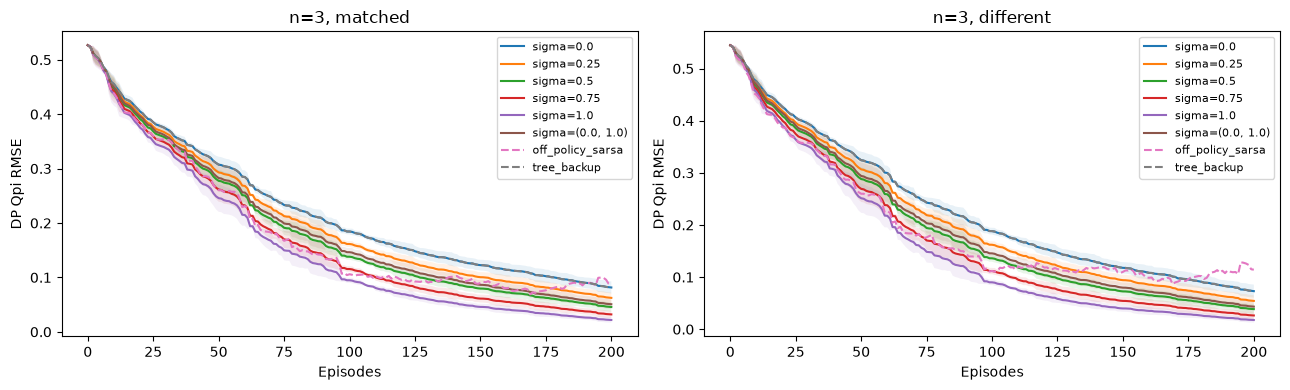

In [59]:
for qs_run in qs_results:
    qs_c,qs_rho = qs_run['coefficients'],qs_run['importance_ratios']
    print(f"seed={qs_run['seed']} {qs_run['target_mode']} sigma={qs_run['sigma']} "
          f"steps=updates={qs_run['steps']} Qpi_RMSE={qs_run['q_rmse']:.6f} "
          f"reward={qs_run['training_rewards'].mean():.3f} length={qs_run['episode_lengths'].mean():.2f} "
          f"c_mean={qs_c.mean():.4f} rho_mean={qs_rho.mean():.4f} rho_max={qs_rho.max():.4f}")
for qs_mode in ('matched','different'):
    for qs_sigma in qs_sigmas:
        qs_errors = [r['q_rmse'] for r in qs_results if r['target_mode']==qs_mode and r['sigma']==qs_sigma]
        print(f'{qs_mode} sigma={qs_sigma}: RMSE mean={np.mean(qs_errors):.6f} std={np.std(qs_errors):.6f}')
fig,axes = plt.subplots(1,2,figsize=(13,4))
for ax,qs_mode in zip(axes,('matched','different')):
    for qs_sigma in qs_sigmas:
        qs_runs = [r for r in qs_results if r['target_mode']==qs_mode and r['sigma']==qs_sigma]
        qs_curves = np.array([[h['q_rmse'] for h in r['history']] for r in qs_runs])
        qs_x = [h['episodes'] for h in qs_runs[0]['history']]
        qs_mean,qs_std = qs_curves.mean(0),qs_curves.std(0)
        ax.plot(qs_x,qs_mean,label=f'sigma={qs_sigma}');ax.fill_between(qs_x,qs_mean-qs_std,qs_mean+qs_std,alpha=.1)
    for qs_algorithm in ('off_policy_sarsa','tree_backup'):
        qs_refs = [r for r in tree_results if r['n']==3 and r['target_mode']==qs_mode and r['algorithm']==qs_algorithm]
        qs_curve = np.mean([[h['q_rmse'] for h in r['history']] for r in qs_refs],axis=0)
        ax.plot([h['episodes'] for h in qs_refs[0]['history']],qs_curve,'--',label=qs_algorithm)
    ax.set(title=f'n=3, {qs_mode}',xlabel='Episodes',ylabel='DP Qpi RMSE');ax.legend(fontsize=8)
plt.tight_layout();plt.show()

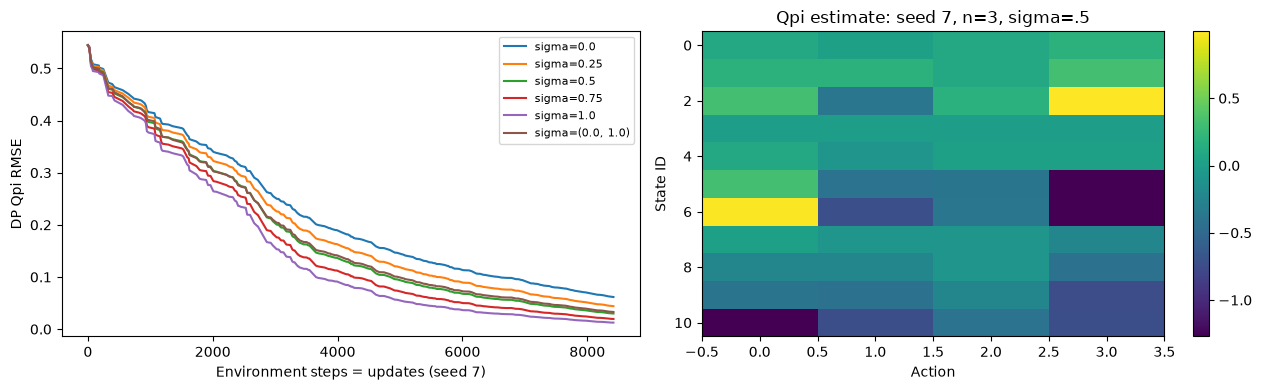

Target pi:
 [[0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]
 [0.3 0.2 0.2 0.3]]
Qpi estimate:
 [[ 0.09593331  0.01951687  0.09659139  0.18596863]
 [ 0.18342098  0.18410958  0.09531025  0.31779393]
 [ 0.31991542 -0.38138814  0.18085294  0.99711271]
 [ 0.          0.          0.          0.        ]
 [ 0.09666929 -0.08740264  0.01936264  0.01931625]
 [ 0.32012347 -0.41005474 -0.39257743 -1.26271464]
 [ 0.98785968 -0.71351356 -0.38375614 -1.26881856]
 [ 0.01891275 -0.08839345 -0.08818848 -0.23092369]
 [-0.23038769 -0.23048211 -0.08712711 -0.42109013]
 [-0.39700868 -0.42091685 -0.2286663  -0.73831932]
 [-1.27080728 -0.72172264 -0.40608199 -0.72712734]]


In [60]:
fig,axes = plt.subplots(1,2,figsize=(13,4))
for qs_sigma in qs_sigmas:
    qs_run = next(r for r in qs_results if r['seed']==7 and r['target_mode']=='different' and r['sigma']==qs_sigma)
    axes[0].plot([h['steps'] for h in qs_run['history']],[h['q_rmse'] for h in qs_run['history']],label=f'sigma={qs_sigma}')
axes[0].set(xlabel='Environment steps = updates (seed 7)',ylabel='DP Qpi RMSE');axes[0].legend(fontsize=8)
qs_table_run = next(r for r in qs_results if r['seed']==7 and r['target_mode']=='different' and r['sigma']==.5)
qs_heat = axes[1].imshow(qs_table_run['q_values'],aspect='auto',cmap='viridis')
axes[1].set(title='Qpi estimate: seed 7, n=3, sigma=.5',xlabel='Action',ylabel='State ID');fig.colorbar(qs_heat,ax=axes[1])
plt.tight_layout();plt.show()
print('Target pi:\n',qs_table_run['target_policy'])
print('Qpi estimate:\n',qs_table_run['q_values'])

### 재사용 결과와 공통화 후보

Model/Estimator/Selector/TransitionBatch/TD0TargetGenerator/TabularQUpdateRule을 변경하지 않았다.
Tree Backup의 Snapshot 확률 계산, Window 검증, SARSA/Tree 비교를 재사용한다.
Q(σ)는 중간 c, 기록된 log b, 저장한 σ를 추가해 Return을 표현한다.

현재 Learner의 고정 max/gather 경로에는 여러 중간 Q·π·σ를 쓰는 재귀를 외부에서 주입할 수 없다.
공통화 후보는 Ordered Window, Online scheduling, boundary flush, sampling-time metadata,
Target 확률 provider, Frozen Q Snapshot과 Return→Update 연결이다. 알고리즘마다 다른 재귀와
Importance 범위를 거대한 조건문에 합치지 않는다. 이번에는 프레임워크를 공통화하지 않는다.

재개에는 Model.state_dict와 고정 π, pending, aligned σ, 현재 선택 action/log b/σ, provider 설정,
n/γ/α, Torch RNG, 환경 위치/RNG/TimeLimit 잔여 예산을 함께 저장한다.
향후 환경모델 신뢰도로 σ를 정한다면, provider가 행동 선택 시점의 예측 신뢰도·불확실성을
명시적으로 참조하고 결정한 σ를 저장해야 한다. 학습 시 과거 σ를 다시 계산하지 않는다.
수식 차이, 수치 안전성, 실제 중복과 최소 인터페이스 후보는 ARCHITECTURE.md에 기록한다.